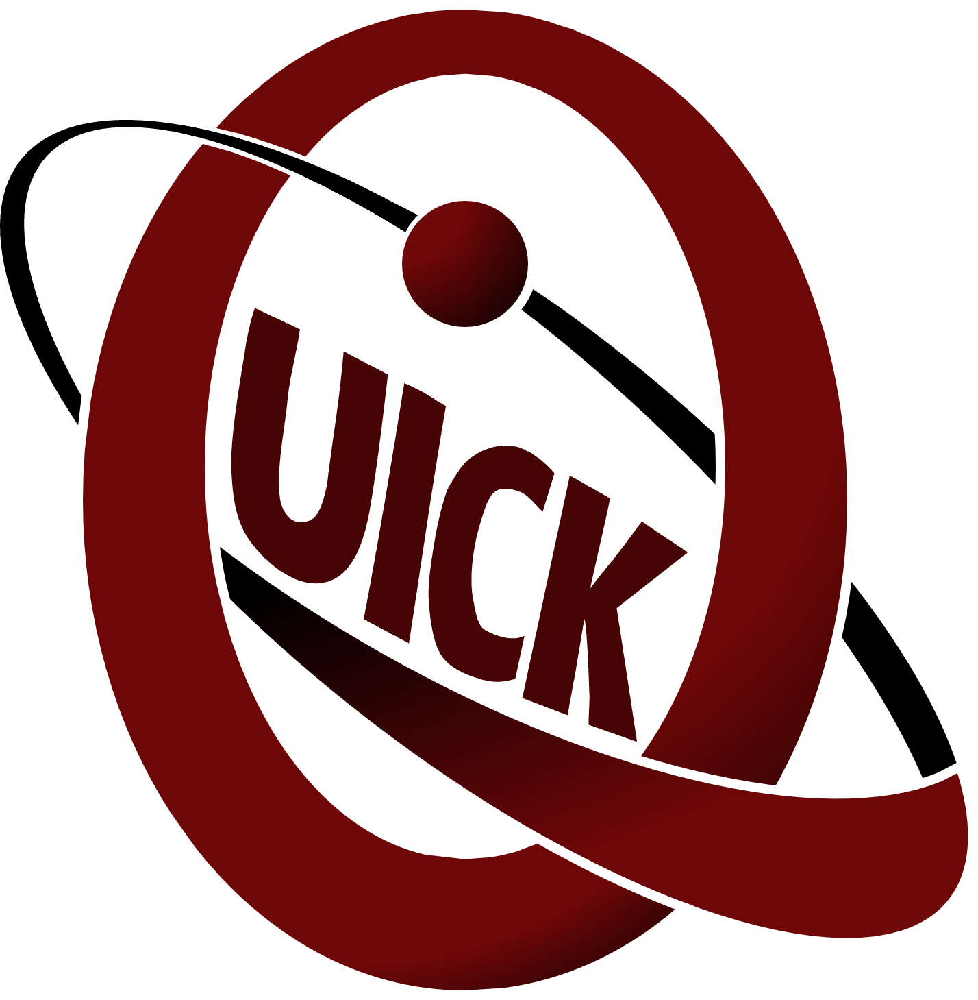

# Q-LINK — 세 실험실을 연결하라

**2026 Qiskit Fall Fest · QUICK · 고려대학교 | 참가자용 v4**

Alice, Bob, Charlie의 세 실험실이 양자 네트워크 개통을 준비합니다. 여러분은 담당 엔지니어로서 측정 장치와 얽힘 자원을 점검하고, Alice의 양자 상태를 Bob에게 전송하는 회로를 복구합니다. 마지막으로 세 실험실이 입력 이후 서로 연락하지 않고 협력할 수 있는지 시험합니다.

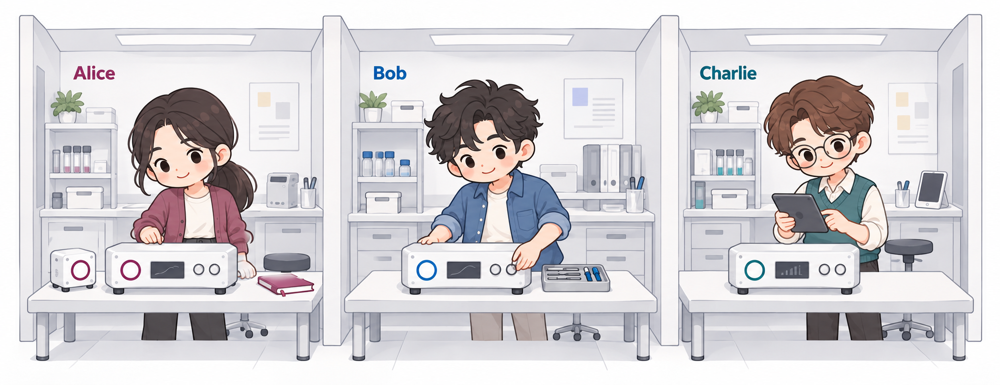

| 개통 시험 | 해결할 과제 | 배점 |
|---|---|---:|
| 1. 측정과 얽힘 | 측정 통계로 상태를 구별하고 공유 자원 준비하기 | 30점 |
| 2. 양자 텔레포테이션 | 전송 회로의 결함을 찾고 상태와 얽힘 복구하기 | 40점 |
| 3. GHZ–Mermin 게임 | 고전 전략과 양자 전략의 협력 성능 비교하기 | 30점 |
| 선택 심화 | 두 큐비트 전송과 위상 오류 분석하기 | 추가 20점 |

[시작하기](#start) · [1. 측정·얽힘](#part1) · [2. 텔레포테이션](#part2) · [3. GHZ–Mermin 게임](#part3) · [선택 심화](#optional) · [보고서·제출](#finish)


<a id="start"></a>

# 시작하기

이 노트북 하나로 **Colab·VS Code·Jupyter**에서 문제 풀이, 자동 채점, 제출 ZIP 생성을 진행합니다. 그림은 노트북에 포함되어 있으며, 처음 패키지를 설치할 때는 인터넷 연결이 필요합니다.

| 실행 환경 | 준비할 사항 |
|---|---|
| Colab | Python CPU 런타임을 사용합니다. |
| VS Code·Jupyter | Python 3.10–3.13 커널을 선택합니다. 로컬 환경은 Python 3.12를 권장합니다. |

Colab에서 GitHub 문제지를 열었다면 자신의 사본으로 저장한 뒤 풀이를 시작하세요.

1. **먼저 준비 A 셀만 실행하세요.** [공식 grader Release v2.0.4](https://github.com/equivoque-jk/qff-2026-grader/releases/tag/v2.0.4)와 실험 도구를 설치합니다. 필요한 버전이 이미 설치되어 있으면 재설치하지 않습니다.
2. **재시작 안내가 나온 경우에만** Colab의 **런타임 → 세션 다시 시작**, 또는 VS Code·Jupyter의 **커널 다시 시작**을 선택하고 준비 A를 다시 실행하세요.
3. 준비 완료 메시지가 나오면 **준비 B·C·D**를 실행하고, 각 파트의 제공 도구와 문제 셀을 위에서부터 진행하세요.
4. 풀이를 마친 뒤 **모두 실행 / Run All**을 선택하면 마지막 셀에서 채점 결과와 제출 ZIP을 생성합니다. **풀이를 작성한 `.ipynb`도 저장**하여 ZIP과 함께 제출하세요.

설치에 실패하면 준비 A의 오류 메시지와 인터넷 연결을 확인하세요. 세션이나 커널을 재시작한 뒤에는 화면에 이전 출력이 남아 있더라도 필요한 셀을 다시 실행해야 합니다.

제출처·마감 시각·제출 단위와 문의 채널은 **행사 공지에 따릅니다.** 자세한 저장 방법은 [보고서·제출](#finish)을 확인하세요.


In [ ]:
#@title 준비 A — 채점 패키지와 실험 환경 준비 (자동)
# GitHub Release의 지정된 버전을 설치합니다. 이미 준비된 환경에서는 재설치하지 않습니다.
import importlib as _qff_importlib
import importlib.metadata as _qff_metadata
import subprocess as _qff_subprocess
import sys as _qff_sys

print("[준비 A 1/4] Python·설치 패키지를 확인합니다.", flush=True)
if not ((3, 10) <= _qff_sys.version_info[:2] < (3, 14)):
    raise RuntimeError("Python 3.10–3.13 커널이 필요합니다. Colab의 Python 런타임 또는 지원 버전의 로컬 커널을 선택하세요.")
try:
    from google.colab import files as _qff_colab_files
except ImportError:
    _qff_is_colab = False
else:
    _qff_is_colab = True

_qff_required = {
    "qff-local-grader": "2.0.4", "qiskit": "2.3.1", "numpy": "2.2.6",
    "psutil": "7.2.2", "qiskit-aer": "0.17.2", "matplotlib": "3.10.8",
    "pylatexenc": "2.10", "ipython": None, "nbformat": None,
}
_qff_colab_ipython = None
if _qff_is_colab:
    # Colab's shell depends on its own IPython version. Preserve the live kernel version.
    _qff_colab_ipython = getattr(_qff_sys.modules.get("IPython"), "__version__", None)
    if _qff_colab_ipython is None:
        _qff_colab_ipython = _qff_metadata.version("ipython")
    _qff_required["ipython"] = _qff_colab_ipython
    print("Colab 커널의 IPython " + _qff_colab_ipython + " 버전을 유지합니다.", flush=True)

_qff_install_needed = False
_qff_before_versions = {}
for _qff_distribution, _qff_expected in _qff_required.items():
    try:
        _qff_actual = _qff_metadata.version(_qff_distribution)
    except _qff_metadata.PackageNotFoundError:
        _qff_before_versions[_qff_distribution] = None
        _qff_install_needed = True
    else:
        _qff_before_versions[_qff_distribution] = _qff_actual
        if _qff_expected is not None and _qff_actual != _qff_expected:
            _qff_install_needed = True

if _qff_install_needed:
    print("[준비 A 2/4] GitHub Release v2.0.4에서 설치할 패키지를 확인합니다.", flush=True)
    _qff_package_url = "https://github.com/equivoque-jk/qff-2026-grader/releases/download/v2.0.4/qff_local_grader-2.0.4-py3-none-any.whl#sha256=19201583ccbfa377cc04ff468cbe43351828022238fc0823eaeca51a2be9991d"
    _qff_modules = {
        "qff-local-grader": "qff_grader", "qiskit": "qiskit", "numpy": "numpy",
        "psutil": "psutil", "qiskit-aer": "qiskit_aer", "matplotlib": "matplotlib",
        "pylatexenc": "pylatexenc", "ipython": "IPython", "nbformat": "nbformat",
    }
    _qff_loaded_before_install = {
        _qff_dist: getattr(_qff_sys.modules[_qff_module], "__version__", None)
        for _qff_dist, _qff_module in _qff_modules.items() if _qff_module in _qff_sys.modules
    }
    _qff_install_command = [
        _qff_sys.executable, "-m", "pip", "install", "--progress-bar", "off",
        "qff-local-grader[notebook] @ " + _qff_package_url,
    ]
    if _qff_colab_ipython:
        _qff_install_command.append("ipython==" + _qff_colab_ipython)
    print("[준비 A 3/4] 패키지 설치를 시작합니다. 아래 로그가 진행 상황입니다. (최대 10분)", flush=True)
    import queue as _qff_queue
    import threading as _qff_threading
    import time as _qff_time
    _qff_process = _qff_subprocess.Popen(
        _qff_install_command, stdout=_qff_subprocess.PIPE, stderr=_qff_subprocess.STDOUT,
        text=True, bufsize=1,
    )
    _qff_lines = _qff_queue.Queue()
    def _qff_read_install_log():
        try:
            for _qff_line in _qff_process.stdout:
                _qff_lines.put(_qff_line)
        finally:
            _qff_lines.put(None)
    _qff_reader = _qff_threading.Thread(target=_qff_read_install_log, daemon=True)
    _qff_reader.start()
    _qff_deadline = _qff_time.monotonic() + 600
    _qff_last_notice = _qff_time.monotonic()
    while True:
        if _qff_time.monotonic() >= _qff_deadline:
            _qff_process.kill()
            _qff_process.wait(timeout=10)
            raise RuntimeError("설치가 10분 제한을 초과하여 중단했습니다. 네트워크 상태를 확인한 뒤 준비 A를 다시 실행하세요.")
        try:
            _qff_line = _qff_lines.get(timeout=1)
        except _qff_queue.Empty:
            if _qff_time.monotonic() - _qff_last_notice >= 30:
                print("설치 프로세스가 실행 중입니다. 다음 설치 로그를 기다립니다.", flush=True)
                _qff_last_notice = _qff_time.monotonic()
            continue
        if _qff_line is None:
            break
        print(_qff_line, end="", flush=True)
    try:
        _qff_returncode = _qff_process.wait(timeout=max(1, _qff_deadline - _qff_time.monotonic()))
    except _qff_subprocess.TimeoutExpired:
        _qff_process.kill()
        _qff_process.wait(timeout=10)
        raise RuntimeError("설치가 10분 제한을 초과했습니다. 준비 A의 설치 로그를 확인하세요.") from None
    if _qff_returncode != 0:
        raise RuntimeError("설치가 완료되지 않았습니다. 위 pip 오류를 확인하고 준비 A를 다시 실행하세요.")
    print("패키지 설치가 완료됐습니다.", flush=True)
    _qff_importlib.invalidate_caches()
    _qff_changed_loaded = [
        _qff_dist for _qff_dist, _qff_loaded_version in _qff_loaded_before_install.items()
        if _qff_before_versions[_qff_dist] != _qff_metadata.version(_qff_dist)
        and _qff_loaded_version != _qff_metadata.version(_qff_dist)
    ]
    if _qff_changed_loaded:
        print("설치 성공. 메모리에 남은 이전 버전: " + ", ".join(_qff_changed_loaded), flush=True)
        raise RuntimeError(
            "런타임 관련 오류입니다. Colab 메뉴 '런타임 → 세션 다시 시작'을 선택한 뒤 "
            "준비 A 셀만 다시 실행하세요. VS Code·Jupyter에서는 커널을 다시 시작한 뒤 준비 A를 실행하세요. "
            "준비 완료 후 준비 B·C·D와 필요한 문제 셀을 순서대로 실행하세요. "
            "'모두 실행'은 전체 답안을 채점하고 제출 ZIP을 만들 때 선택합니다."
        )
else:
    print("[준비 A 2–3/4] 필요한 버전이 설치되어 있습니다. 설치를 건너뜁니다.", flush=True)

print("[준비 A 4/4] 실제 로드된 버전과 실험 환경을 확인합니다.", flush=True)
import qff_grader as _qff_package
if _qff_package.__version__ != "2.0.4":
    raise RuntimeError("이전 채점 패키지가 메모리에 남아 있습니다. Colab은 '런타임 → 세션 다시 시작', VS Code·Jupyter는 커널 재시작 후 준비 A를 다시 실행하세요.")
from qff_grader import check_runtime, reset_submission_state, finalize_submission
_qff_runtime = check_runtime(require_notebook=True)
reset_submission_state(globals())
print("QFF 2.0.4 준비 완료 — 준비 B·C·D와 필요한 문제 셀을 순서대로 실행하며 TODO를 작성하세요.", flush=True)
print("전체 답안을 채점하고 제출 ZIP을 만들 때 Colab은 '런타임 → 모두 실행', VS Code·Jupyter는 'Run All'을 선택하세요.", flush=True)


In [ ]:
#@title 준비 B — 설치 버전 확인
import sys, qiskit, qiskit_aer, numpy, matplotlib
print("Python", sys.version.split()[0])
print("Qiskit", qiskit.__version__, "Aer", qiskit_aer.__version__)
print("NumPy", numpy.__version__, "Matplotlib", matplotlib.__version__)
assert qiskit.__version__ == "2.3.1" and qiskit_aer.__version__ == "0.17.2"

In [ ]:
#@title 준비 C — 공용 실행 도구
"""Provided helpers, embedded into each notebook so Colab needs no local files."""
import itertools
import numpy as np
from qiskit import QuantumCircuit, ClassicalRegister, transpile
from qiskit.circuit import Clbit
from qiskit.quantum_info import Statevector, DensityMatrix, partial_trace, state_fidelity
from qiskit_aer import AerSimulator
from IPython.display import display

SHOTS = 4096
SEED = 20260909
BACKEND = AerSimulator(max_parallel_threads=2)


def compile_for_aer(qc, seed=SEED):
    # Lower state preparation to portable gates, avoiding backend-specific
    # multiplexer instructions. This also works inside classical if blocks.
    return transpile(qc, basis_gates=["u", "cx"], optimization_level=0,
                     seed_transpiler=seed, num_processes=1)

"""Circuit contract for educational checks; not a Python security sandbox."""
from qiskit.circuit import Barrier, Clbit, IfElseOp
from qiskit.circuit.library import HGate, XGate, ZGate, CXGate, SGate, SdgGate


def validate_fragment(qc, nq, nc=0, allowed=("h", "x", "z", "cx"), conditional=False):
    """Check standard gate identity and arity, including conditional bodies."""
    if not isinstance(qc, QuantumCircuit) or (qc.num_qubits, qc.num_clbits) != (nq, nc):
        raise ValueError(f"Expected QuantumCircuit({nq}, {nc})")
    if qc.parameters:
        raise ValueError("Bind all circuit parameters before submission")
    standard = {"h": HGate, "x": XGate, "z": ZGate, "cx": CXGate,
                "s": SGate, "sdg": SdgGate}
    for item in qc.data:
        op = item.operation
        if type(op) is Barrier:
            continue
        if type(op) is IfElseOp and conditional:
            condition = op.condition
            if not isinstance(condition, tuple) or len(condition) != 2:
                raise ValueError("Use a single local classical bit in if_test")
            bit, value = condition
            if not isinstance(bit, Clbit) or value not in (0, 1) or bit not in qc.clbits:
                raise ValueError("Use a single local classical bit in if_test")
            for block in op.blocks:
                validate_fragment(block, block.num_qubits, block.num_clbits, allowed, True)
            continue
        gate_class = standard.get(op.name)
        if op.name not in allowed or gate_class is None:
            raise ValueError(f"Operation not allowed here: {op.name}")
        canonical = gate_class()
        if (type(op) not in (gate_class, type(canonical)) or
                op.num_qubits != canonical.num_qubits or op.num_clbits or op.params or
                (op.name == "cx" and op.ctrl_state != canonical.ctrl_state)):
            raise ValueError(f"Use the standard Qiskit gate for {op.name}")
    return qc


def bit_at(key, index):
    """Global classical-bit index; independent of printed register separators."""
    return int(key.replace(" ", "")[-1-index])

_qff_experiment_errors = []


def _qff_record_experiment_error(label, exc):
    _qff_experiment_errors.append({"experiment": label, "type": type(exc).__name__, "message": str(exc)})
    print(f"실험 점검 — {label}: {type(exc).__name__}: {exc}")
    print("이 실험의 출력은 건너뜁니다. 마지막 자동 채점에서 문항별 결과를 확인하세요.")


def run_if_ready(action):
    """Keep ordinary unfinished/incorrect experiment output from blocking grading."""
    try:
        return action()
    except NotImplementedError as exc:
        print(f"미완성 — 해당 TODO를 구현한 뒤 다시 실행하세요: {exc}")
    except Exception as exc:
        _qff_record_experiment_error(getattr(action, "__name__", "실험"), exc)


from contextlib import contextmanager as _qff_contextmanager


@_qff_contextmanager
def _qff_experiment(label):
    """Preserve module-level experiment variables while reporting ordinary errors."""
    try:
        yield
    except NotImplementedError as exc:
        print(f"미완성 — 해당 TODO를 구현한 뒤 다시 실행하세요: {exc}")
    except Exception as exc:
        _qff_record_experiment_error(label, exc)

def show_game(report):
    print("input       correlator    win rate")
    for row in report["rows"]:
        xyz = "".join(map(str, row["input"]))
        print(f"{xyz:>5s}       {row['correlator']: .6f}    {row['win_rate']:.6f}")
    print(f"average win={report['p_win']:.6f}, M={report['M']:.6f}")

def show_fidelity(report):
    print(f"F_hat={report['fidelity']:.6f}")
    print("Alice bits     shots    branch F_hat")
    for bits, row in report["branches"].items():
        print(f"{bits:>10s}     {row['shots']:5d}    {row['fidelity']:.6f}")


In [ ]:
#@title 준비 D — 측정·그림 도구
"""Provided measurement helpers for the integrated QFF notebook."""
import matplotlib.pyplot as plt
from qiskit.quantum_info import SparsePauliOp

COLORS = {"A": "#4169A1", "B": "#B77933", "reference": "#333B45"}
plt.rcParams.update({"figure.figsize": (9, 3.6), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "semibold", "figure.dpi": 120})


def initial_one_qubit(label):
    qc = QuantumCircuit(1)
    if label == "1":
        qc.x(0)
    elif label == "+":
        qc.h(0)
    elif label == "-":
        qc.x(0)
        qc.h(0)
    elif label != "0":
        raise ValueError("Use one of: 0, 1, +, -")
    return qc


def measure_subset(preparation, qubits, readout=None, shots=SHOTS, seed=SEED):
    """Each call prepares a fresh state, changes basis, then measures only listed qubits."""
    if preparation.num_clbits or shots < 1 or len(set(qubits)) != len(qubits):
        raise ValueError("Use an unmeasured preparation and distinct measured qubits")
    qc = preparation.copy()
    if readout is not None:
        validate_fragment(readout, len(qubits), allowed=("h", "x", "z", "s", "sdg"))
        qc.compose(readout, list(qubits), inplace=True)
    bits = ClassicalRegister(len(qubits), "readout")
    qc.add_register(bits)
    qc.measure(list(qubits), bits)
    counts = BACKEND.run(compile_for_aer(qc, seed), shots=shots,
                         seed_simulator=seed).result().get_counts()
    return counts


def expectation_from_counts(counts):
    total = sum(counts.values())
    if total <= 0:
        raise ValueError("Counts must contain at least one shot")
    return sum((-1)**key.replace(" ", "").count("1") * n for key, n in counts.items()) / total


def inspect_one(builder):
    qc = validate_fragment(builder(), 1)
    counts = measure_subset(qc, [0])
    display(qc.draw("mpl"))
    print("counts:", counts)
    print(f"<Z> estimate = {expectation_from_counts(counts):+.6f}")
    return counts


def inspect_four_states(builder, readout=None, draw=False):
    rows = []
    for i, label in enumerate(("0", "1", "+", "-")):
        qc = validate_fragment(builder(label), 1)
        counts = measure_subset(qc, [0], readout, seed=SEED+i)
        ev = expectation_from_counts(counts)
        rows.append((label, ev))
        if draw:
            print("Initial state:", label)
            display(qc.draw("mpl"))
    print("initial      expectation estimate")
    for label, ev in rows:
        print(f"{label:>7s}      {ev:+.6f}")
    return rows


BELL_TARGETS = {
    "Phi+": Statevector(np.array([1, 0, 0, 1])/np.sqrt(2)),
    "Phi-": Statevector(np.array([1, 0, 0, -1])/np.sqrt(2)),
    "Psi+": Statevector(np.array([0, 1, 1, 0])/np.sqrt(2)),
    "Psi-": Statevector(np.array([0, 1, -1, 0])/np.sqrt(2)),
}


def bell_experiment(transform, target):
    qc = QuantumCircuit(2)
    qc.x(0)  # Referee fixes |q1 q0> = |01>; participant cannot remove this prefix.
    qc.barrier(label="given input 01")
    qc.compose(validate_fragment(transform(target), 2), inplace=True)
    return qc


def inspect_bells(transform):
    print("target      preparation fidelity")
    for label, target in BELL_TARGETS.items():
        qc = bell_experiment(transform, label)
        print(f"{label:>6s}      {state_fidelity(Statevector(qc), target):.6f}")
        display(qc.draw("mpl"))


def plot_readout_comparison(counts_a, counts_b, title, parity=False):
    def probabilities(counts):
        n = sum(counts.values())
        if parity:
            return [sum(v for k, v in counts.items() if k.count("1") % 2 == p)/n for p in (0, 1)]
        width = len(next(iter(counts)))
        return [counts.get(f"{i:0{width}b}", 0)/n for i in range(2**width)]
    a, b = probabilities(counts_a), probabilities(counts_b)
    labels = ["even (+1)", "odd (-1)"] if parity else [f"{i:03b}" for i in range(len(a))]
    positions = np.arange(len(a))
    fig, ax = plt.subplots(figsize=(9, 3.4), layout="constrained")
    ax.bar(positions-0.18, a, width=0.36, label="Device A", color=COLORS["A"])
    ax.bar(positions+0.18, b, width=0.36, label="Device B", color=COLORS["B"], hatch="//")
    ax.set(xticks=positions, xticklabels=labels, ylim=(0, 1.08),
           ylabel="Observed fraction", xlabel="Output parity" if parity else "Measured bits (q2 q1 q0)", title=title)
    ax.legend(frameon=False, ncol=2)
    ax.text(1, 1.03, f"{sum(counts_a.values())} shots/device", transform=ax.transAxes, ha="right", fontsize=9)
    plt.show()


def inspect_sources(build_a, build_b, readout=None):
    a = validate_fragment(build_a(), 3)
    b = validate_fragment(build_b(), 4)
    counts_a = measure_subset(a, [0, 1, 2], readout, seed=SEED)
    counts_b = measure_subset(b, [0, 1, 2], readout, seed=SEED+1)
    print("Device A parity expectation:", f"{expectation_from_counts(counts_a):+.6f}")
    print("Device B parity expectation:", f"{expectation_from_counts(counts_b):+.6f}")
    plot_readout_comparison(counts_a, counts_b,
                           "Local Z readout" if readout is None else "Readout after your basis change",
                           parity=readout is not None)
    return counts_a, counts_b


def plot_game_comparison(ghz_report, coin_report):
    fig, (by_input, average) = plt.subplots(
        1, 2, figsize=(10.5, 4), gridspec_kw={"width_ratios": [1.5, 1]}, layout="constrained")
    x = np.arange(4)
    by_input.bar(x-0.18, [r["win_rate"] for r in ghz_report["rows"]], 0.36,
                 label="GHZ", color=COLORS["A"])
    by_input.bar(x+0.18, [r["win_rate"] for r in coin_report["rows"]], 0.36,
                 label="Coin", color=COLORS["B"], hatch="//")
    by_input.set(xticks=x, xticklabels=["000", "011", "101", "110"], ylim=(0, 1.1),
                 yticks=[0, .25, .5, .75, 1], yticklabels=["0%", "25%", "50%", "75%", "100%"],
                 xlabel="Input (x y z)", ylabel="Observed win rate", title="Each input: same X/Y strategy")
    by_input.legend(frameon=False, ncol=2)
    scores = [ghz_report["p_win"], coin_report["p_win"]]
    bars = average.bar([0, 1], scores, width=.55, color=[COLORS["A"], COLORS["B"]])
    bars[1].set_hatch("//")
    average.axhline(.75, color=COLORS["reference"], linestyle="--", linewidth=1.2)
    average.text(.98, .76, "Best classical: 75%", ha="right", va="bottom", fontsize=9,
                 transform=average.get_yaxis_transform())
    average.bar_label(bars, labels=[f"{score:.1%}" for score in scores], padding=4)
    average.set(xticks=[0, 1], xticklabels=["GHZ", "Coin"], ylim=(0, 1.16),
                yticks=[0, .25, .5, .75, 1], yticklabels=["0%", "25%", "50%", "75%", "100%"],
                title="Uniform-input average")
    plt.show()


<a id="rules"></a>

## 답안 작성과 실험 규칙

**23개 답안 함수의 `TODO BEGIN`과 `TODO END` 사이만 작성합니다.** 해당 영역의 `raise NotImplementedError(...)`를 지우고 구현하세요. 함수 선언, 제공된 초기화 코드, 마지막 `return`, 제공 도구·실행·채점 셀은 그대로 둡니다. 선택 문항을 풀지 않을 때는 해당 TODO를 그대로 두세요.

| 구분 | 작성·확인할 내용 |
|---|---|
| 답안 함수 | 문항에서 정한 회로 또는 수치 결과를 반환합니다. |
| 문제별 실행 셀 | 회로와 실험 결과를 관찰합니다. 일부 실행 셀은 수치 답안 함수를 호출하지 않으므로 각 문항의 안내를 확인하세요. |
| 마지막 채점 셀 | 답안 함수의 반환값을 검사하고 제출 ZIP을 생성합니다. |
| 실험 메모·개통 보고서 | 관찰과 계산 근거를 기록합니다. 자동 채점 대상은 아닙니다. |

**회로 작성 규칙**

- 회로 크기와 반환 형식은 각 문항의 지시를 따릅니다. 제출 회로에 측정·`reset`·추가 큐비트·측정 결과에 따른 표본 선별(postselection)을 넣지 마세요. 필요한 측정은 제공 코드가 연결합니다.
- 기본 허용 게이트는 **H/X/Z/CX**입니다. 국소 측정 변환은 **H/X/Z**를 사용하며, **3-2의 `local_basis()`에만 S/S†를 추가로 허용**합니다. 국소 연산은 각자 가진 큐비트에만 적용합니다.
- Bob의 보정은 **H/X/Z와 `if_test`**를 사용합니다. 조건은 반환 회로의 고전 비트 **하나를 0 또는 1과 비교**해야 합니다. 여러 비트를 확인할 때는 조건문을 중첩합니다. 고전 레지스터 전체의 정수값 비교나 고전 논리식을 조건으로 사용하는 방식은 허용하지 않습니다.
- **1-1~1-3은 게이트의 종류·횟수·순서도 검사**합니다. 같은 최종 상태를 만들더라도 추가 게이트를 넣거나 제공된 초기화 부분을 바꾸지 마세요. 회로 구분용 `barrier`는 게이트 목록 검사에서 제외합니다.
- 함수는 자신의 인자와 공개된 문제 정의만 사용합니다. 전역 위상만 다른 상태는 같은 상태로 취급합니다.

**표기와 수치 결과**

- 상태·결과 문자열은 높은 인덱스가 왼쪽입니다. 예를 들어 두 큐비트 상태는 $|q_1q_0\rangle$, 두 고전 비트 결과는 `c1c0` 순서이며, q0·c0는 가장 오른쪽에 놓입니다.
- 이상적인 Aer 시뮬레이터를 사용합니다. 표본 실험은 측정 설정당 **4096 shots**이며, 매 shot마다 초기 상태를 새로 준비합니다. counts는 결과별 관측 횟수입니다.
- 표본 기댓값·승률·fidelity는 관찰과 비교에 사용합니다. **수치 답안에는 이상적 회로의 정확한 확률·밀도행렬에서 계산한 값을 반환**하세요. 특정 counts와의 일치는 요구하지 않습니다.

2-1과 선택 2-5에서 제공한 고장 회로의 실패 메시지는 결함을 찾기 위한 실험 결과입니다. 해당 문항의 지시에 따라 원인을 분석하고 수정하세요.

<a id="part1"></a>

# 1. 측정과 얽힘 — 장비 점검

전송 시험에 앞서 측정 장치와 공유 자원을 점검합니다. 한 큐비트의 측정 통계부터 시작해, 같은 Z 측정 분포를 갖는 상태도 다른 측정으로 구별할 수 있는지 확인하세요. 이어서 두 실험실의 Bell 자원과 세 실험실의 GHZ 자원을 준비합니다.

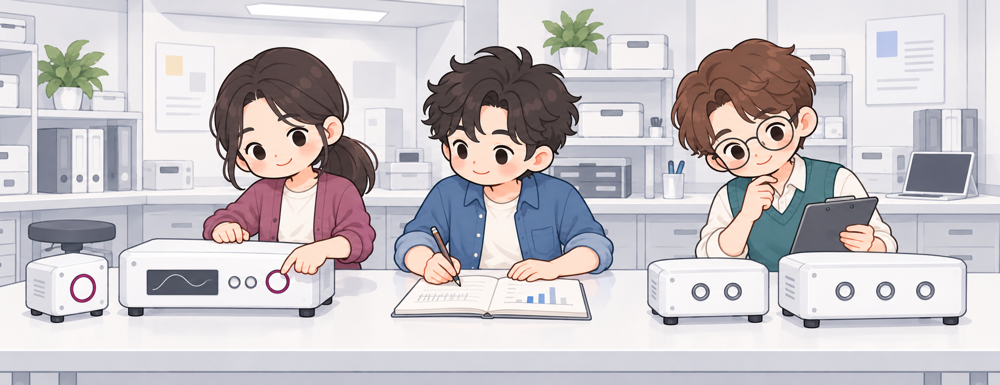


## 1-1. 기준 상태 점검 — X 게이트 적용 후 Z 기댓값 · 3점

`build_circuit_1_1()`에서 초기 상태 $|0\rangle$에 **X를 한 번** 적용하세요. 측정이 없는 `QuantumCircuit(1)`을 반환합니다.

아래 **「실행 1-1 — 회로·counts·Z 기댓값 확인」** 셀은 여러분이 반환한 회로의 복사본에 Z 기저 측정을 추가하여 4096회 실행합니다. counts와 Z 기댓값 추정치를 출력합니다. 회로 그림에는 여러분이 작성한 **측정 전 회로만** 표시됩니다.

**채점 사항:** 반환 회로의 크기·허용 게이트와 준비 상태를 검사합니다. `barrier`를 제외한 전체 게이트 목록은 X 하나여야 하며, 최종 상태가 같아지는 추가 게이트도 허용하지 않습니다. 위 4096-shot 출력은 관찰용이며, 채점기는 반환 회로가 준비하는 상태를 직접 계산해 확인합니다.

counts에서 0과 1이 나온 횟수를 각각 $N_0,N_1$, 총 측정 횟수를 $N$이라 하면 Z 기댓값의 표본 추정치는 $(N_0-N_1)/N$입니다.

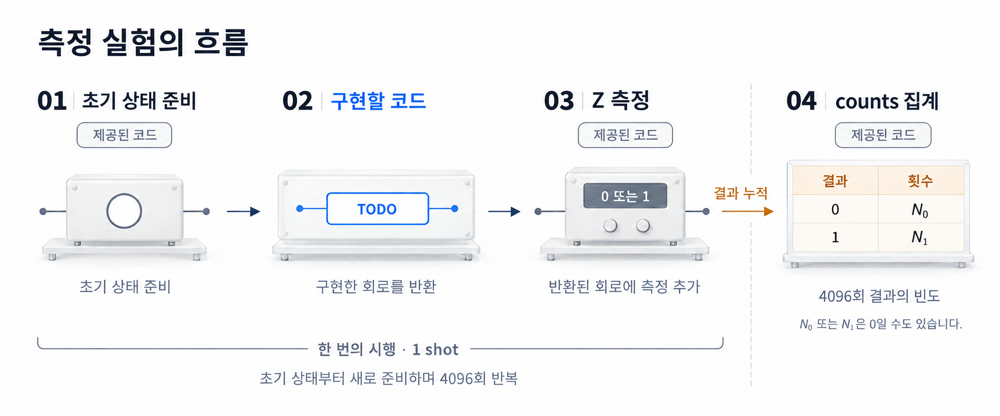

*각 shot에서 초기 상태를 새로 준비하고, 구현한 회로 뒤에 제공 코드가 Z 측정을 추가합니다.*


In [ ]:
# 직접 작성 1-1 — TODO BEGIN과 TODO END 사이만 작성하세요.
def build_circuit_1_1():
    "|0>에 X 한 번. 1-qubit 측정 없는 회로 반환"
    qc = QuantumCircuit(1)
    # TODO BEGIN — 아래 raise를 지우고 필요한 계산/연산을 작성하세요.
    raise NotImplementedError("build_circuit_1_1")
    # TODO END
    return qc


In [ ]:
#@title 실행 1-1 — 회로·counts·Z 기댓값 확인
result_1_1 = run_if_ready(lambda: inspect_one(build_circuit_1_1))

**실험 메모 1-1 · 채점 제외**

- Z 측정 결과 0과 1은 각각 어떤 부호의 측정값에 대응하나요?
- 관찰한 counts로 Z 기댓값을 계산하고, 회로에서 구한 이론값과 비교하세요.

관찰·계산·해석:

…


## 1-2. 기준 상태 점검 — H와 측정 통계 · 3점

`build_circuit_1_2()`에서 초기 상태 $|0\rangle$에 **H를 한 번** 적용하세요. 측정이 없는 `QuantumCircuit(1)`을 반환합니다.

아래 **「실행 1-2 — H 실험과 1-1 비교」** 셀은 반환 회로의 복사본에 Z 기저 측정을 추가하여 4096회 실행합니다. 회로 그림에는 측정 전 회로만 표시됩니다. counts와 Z 기댓값 추정치를 확인하세요.

**채점 사항:** 반환 회로의 크기·허용 게이트와 준비 상태를 검사합니다. `barrier`를 제외한 전체 게이트 목록은 H 하나여야 하며, 최종 상태가 같아지는 추가 게이트도 허용하지 않습니다. 4096-shot 출력은 관찰용이며, 특정 counts와의 일치는 요구하지 않습니다.


In [ ]:
# 직접 작성 1-2 — TODO BEGIN과 TODO END 사이만 작성하세요.
def build_circuit_1_2():
    "|0>에 H 한 번. 1-qubit 측정 없는 회로 반환"
    qc = QuantumCircuit(1)
    # TODO BEGIN — 아래 raise를 지우고 필요한 계산/연산을 작성하세요.
    raise NotImplementedError("build_circuit_1_2")
    # TODO END
    return qc


In [ ]:
#@title 실행 1-2 — H 실험과 1-1 비교
result_1_2 = run_if_ready(lambda: inspect_one(build_circuit_1_2))

**실험 메모 1-2 · 채점 제외**

- counts를 총 shots 수로 나누어 0과 1의 상대도수를 구하고, 이론적 확률과 비교하세요.
- Z 기댓값의 추정치와 이론값을 비교하고, 1-1의 결과와 어떤 차이가 있는지 설명하세요.

관찰·계산·해석:

…


## 1-3. 기준 상태 점검 — H 두 번 · 4점

`build_circuit_1_3(initial_state)`에 제공된 초기 회로에 **H 게이트를 두 번 차례로 적용**하세요. 기존 초기화 부분을 유지한 측정 없는 `QuantumCircuit(1)`을 반환합니다. `initial_state`는 `"0"`, `"1"`, `"+"`, `"-"` 중 하나입니다.

아래 실행 셀은 네 초기 상태에 H를 두 번 적용한 회로 뒤에 Z 기저 측정을 추가하여 기댓값을 추정합니다. 네 초기 상태에 대한 결과를 확인하세요.

**채점 사항:** 네 입력에 대한 초기 상태 준비와 최종 상태를 검사합니다. `barrier`를 제외한 전체 게이트 목록은 제공된 초기화 연산 뒤에 H 두 개를 차례로 붙인 형태여야 합니다. 최종 상태가 같더라도 초기화 연산을 바꾸거나 다른 게이트를 추가하면 이 조건을 충족하지 못합니다.


In [ ]:
# 직접 작성 1-3 — TODO BEGIN과 TODO END 사이만 작성하세요.
def build_circuit_1_3(initial_state):
    qc = initial_one_qubit(initial_state)
    # TODO BEGIN — 아래 raise를 지우고 필요한 계산/연산을 작성하세요.
    raise NotImplementedError("build_circuit_1_3")
    # TODO END
    return qc


In [ ]:
#@title 실행 1-3 — 네 초기 상태 비교
result_1_3 = run_if_ready(lambda: inspect_four_states(build_circuit_1_3, draw=True))

**실험 메모 1-3 · 채점 제외**

- 네 초기 상태에 H를 두 번 적용했을 때 각각 어떤 상태가 되는지 계산과 실험 결과를 비교하세요.
- 서로 다르지만 같은 이론적 Z 측정 분포를 갖는 초기 상태는 무엇인가요?

관찰·계산·해석:

…


## 1-4. 측정 기저로 상태 구별하기 · 5점

$|+\rangle$와 $|-\rangle$를 구별하는 공통 단일 큐비트 변환 `discrimination_basis()`를 설계하세요. 측정이 없는 `QuantumCircuit(1)`을 반환합니다. 이 함수는 후보 정보를 입력받지 않습니다. 제공 실험 코드는 모든 후보 상태에 같은 변환을 적용한 뒤 Z 기저로 측정합니다.

아래 실행 셀은 네 후보 `0`, `1`, `+`, `-` 각각에 대해 **변환 없이 Z를 측정한 기댓값**과 **여러분의 변환을 적용한 뒤 Z를 측정한 기댓값**을 출력합니다. 두 측정 설정에는 각각 새로 준비한 상태를 사용합니다.

**힌트:** Z 측정 직전의 변환 $V$는 원래 상태의 $V^\dagger ZV$ 측정과 같습니다. $HZH=X$를 이용하세요.

**채점 사항:** 공통 국소 변환이 `+`와 `-`를 구별하는지 확인합니다. 측정 결과의 부호가 뒤집힌 동등한 구현도 허용합니다.

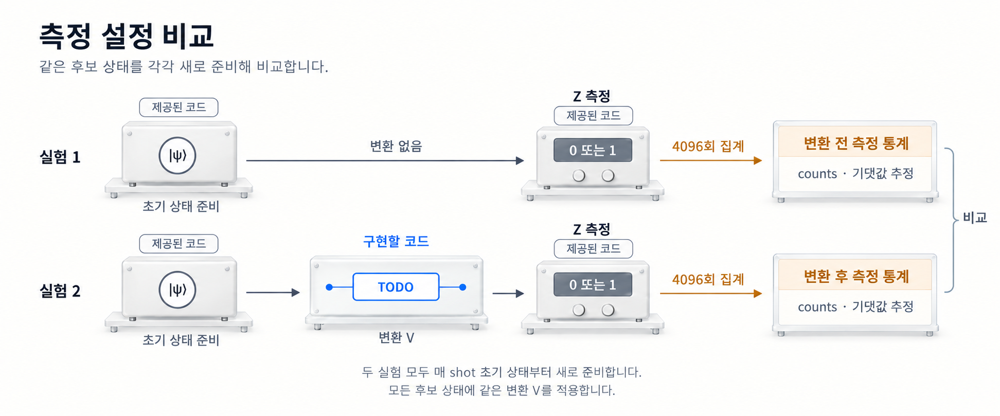

*두 측정 설정은 각각 새로 준비한 상태에 적용합니다. 모든 후보에 공통 변환 V를 사용하세요.*


In [ ]:
# 직접 작성 1-4 — TODO BEGIN과 TODO END 사이만 작성하세요.
def discrimination_basis():
    "어떤 후보인지 알 수 없는 1-qubit 공통 basis 변환. 측정 없음"
    qc = QuantumCircuit(1)
    # TODO BEGIN — 아래 raise를 지우고 필요한 계산/연산을 작성하세요.
    raise NotImplementedError("discrimination_basis")
    # TODO END
    return qc


In [ ]:
#@title 실행 1-4 — 기존 측정과 새 측정 비교
def inspect_discrimination():
    readout = validate_fragment(discrimination_basis(), 1, allowed=("h", "x", "z"))
    display(readout.draw("mpl"))
    print("Z readout")
    inspect_four_states(initial_one_qubit)
    print("New readout on fresh copies")
    return inspect_four_states(initial_one_qubit, readout)

result_1_4 = run_if_ready(inspect_discrimination)

**실험 메모 1-4 · 채점 제외**

- 네 후보 상태 각각에 대해, 직접 Z 측정한 기댓값과 여러분의 변환 후 Z 측정한 기댓값을 비교하세요.
- 같은 후보 상태를 여러 번 준비해 두 측정 설정의 통계를 비교하는 경우와, 네 후보 중 어느 것인지 모르는 한 사본만 받는 경우에는 상태를 판별할 수 있는 조건이 어떻게 다른가요?

관찰·계산·해석:

…


## 1-5. 전송 자원 준비 — 네 가지 Bell 상태 · 7점

지정된 초기 상태 $|q_1q_0\rangle=|01\rangle$ 뒤에 붙일 `bell_transform(target)`를 작성하세요. 함수는 **변환 부분만 담은** 측정 없는 `QuantumCircuit(2)`를 반환합니다. 초기 X는 제공 코드가 적용합니다. `target`은 `"Phi+"`, `"Phi-"`, `"Psi+"`, `"Psi-"`입니다.

$$|\Phi^\pm\rangle=\frac{|00\rangle\pm|11\rangle}{\sqrt2},\qquad
|\Psi^\pm\rangle=\frac{|01\rangle\pm|10\rangle}{\sqrt2}.$$

**Fidelity(상태 일치도)**는 준비한 상태가 목표 상태와 얼마나 일치하는지를 나타내며 0과 1 사이의 값입니다. 순수한 목표 상태 $|\phi\rangle$와 실제 상태 $\rho$에 대해 $F=\langle\phi|\rho|\phi\rangle$로 정의합니다. $F=1$이면 목표 상태와 일치합니다. 위 초기 상태 $|q_1q_0\rangle=|01\rangle$에서는 q0가 1, q1이 0입니다.

아래 **「실행 1-5 — 네 Bell 목표 확인」** 셀에서 각 회로가 준비한 상태와 해당 목표 Bell 상태 사이의 fidelity를 확인하세요. 이 셀은 회로 그림과 fidelity를 출력합니다.

**채점 사항:** 지정 초기 상태에 반환 회로를 연결했을 때 네 목표 상태가 준비되는지 확인합니다. 전역 위상 차이는 무시하며, 같은 목표 상태를 준비하는 다른 회로 구현도 허용합니다.


In [ ]:
# 직접 작성 1-5 — TODO BEGIN과 TODO END 사이만 작성하세요.
def bell_transform(target):
    "고정된 |01> 뒤에 붙일 2-qubit 변환 회로"
    qc = QuantumCircuit(2)
    # TODO BEGIN — 아래 raise를 지우고 필요한 계산/연산을 작성하세요.
    raise NotImplementedError("bell_transform")
    # TODO END
    return qc


In [ ]:
#@title 실행 1-5 — 네 Bell 목표 확인
run_if_ready(lambda: inspect_bells(bell_transform))

**실험 메모 1-5 · 채점 제외**

- 각 Bell 상태의 ⟨ZZ⟩와 ⟨XX⟩ 이론값을 계산해 아래 표를 채우세요.
- Φ 계열과 Ψ 계열 각각에서 +와 − 상태를 비교하세요. 상대 위상의 차이가 두 기댓값에 어떤 차이를 만드나요?

| 목표 상태 | ⟨ZZ⟩ | ⟨XX⟩ |
|---|---|---|
| Phi+ | … | … |
| Phi− | … | … |
| Psi+ | … | … |
| Psi− | … | … |

관찰·계산·해석:

…


## 1-6. 공유 자원 검수 — 같은 Z 측정 분포를 갖는 두 장치 · 8점

세 실험실에 배분할 두 공유 자원을 준비하고 비교합니다.

| 장치 | 배분할 자원 | 작성할 함수와 반환 회로 |
|---|---|---|
| A · GHZ | $\lvert GHZ^+\rangle=(\lvert 000\rangle+\lvert 111\rangle)/\sqrt2$ | `build_ghz_state()` · 측정 없는 `QuantumCircuit(3)` |
| B · Coin | 공정한 동전의 결과에 따라 000 또는 111을 준비한 혼합 상태 | `build_coin_flip_state()` · 측정 없는 `QuantumCircuit(4)` |

두 장치 모두 Alice·Bob·Charlie에게 각각 q0·q1·q2를 배분합니다. **Coin의 q3는 상태 준비 후 접근할 수 없는 기록계**입니다. q3를 제외한 q0·q1·q2의 상태가 위 Coin 자원의 혼합 상태와 같아야 합니다. q3의 결과로 표본을 고르지 마세요.

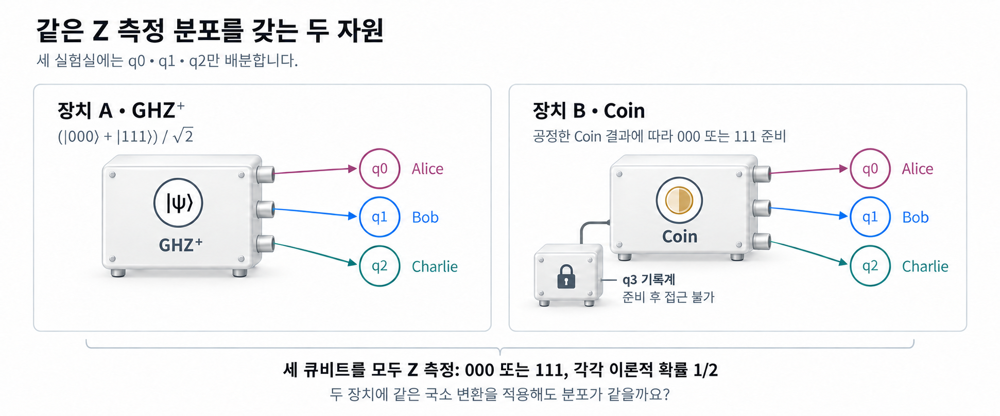

**두 자원의 차이를 드러낼 측정 설정을 설계하세요.** `correlation_basis()`는 H/X/Z만 사용한 측정 없는 `QuantumCircuit(3)`을 반환합니다. GHZ와 Coin에 **동일한 변환 회로**를 적용해야 하며, q0·q1·q2 각각의 국소 연산은 서로 달라도 됩니다.

1. **준비 확인:** 첫 실행 셀에서 변환 없이 Z 측정한 두 자원의 분포를 비교합니다.
2. **판별 실험:** 다음 실행 셀에서 여러분의 국소 변환 뒤에 Z 측정을 추가한 결과를 비교합니다.

한 shot의 결과를 $a,b,c$라 할 때 부호곱을 $(-1)^{a+b+c}$로 정의합니다. 1의 개수가 짝수이면 +1, 홀수이면 −1입니다. 출력의 **parity 기댓값은 이 부호곱의 표본평균**입니다. 같은 이론적 분포라도 유한한 shots에서 얻은 counts가 정확히 같을 필요는 없습니다.

**힌트:** Coin 준비에는 q3에 H를 적용한 뒤, q3에서 q0·q1·q2로 CX를 적용하는 방법을 사용할 수 있습니다.

**채점 사항:** GHZ 상태 준비, q3를 제외한 Coin의 혼합 상태, 같은 국소 측정으로 두 자원의 차이를 드러내는지 확인합니다.


In [ ]:
# 직접 작성 1-6 — TODO BEGIN과 TODO END 사이만 작성하세요.
def build_ghz_state():
    "3-qubit GHZ+ 준비 회로. 측정 없음"
    qc = QuantumCircuit(3)
    # TODO BEGIN — 아래 raise를 지우고 필요한 계산/연산을 작성하세요.
    raise NotImplementedError("build_ghz_state")
    # TODO END
    return qc


In [ ]:
# 직접 작성 1-6 — TODO BEGIN과 TODO END 사이만 작성하세요.
def build_coin_flip_state():
    "q3를 무시하면 동전 장치가 되는 4-qubit 준비 회로"
    qc = QuantumCircuit(4)
    # TODO BEGIN — 아래 raise를 지우고 필요한 계산/연산을 작성하세요.
    raise NotImplementedError("build_coin_flip_state")
    # TODO END
    return qc


In [ ]:
#@title 실행 1-6 — 준비 확인 — 두 장치의 상태·Z 통계
def inspect_source_preparations():
    display(validate_fragment(build_ghz_state(), 3).draw("mpl"))
    display(validate_fragment(build_coin_flip_state(), 4).draw("mpl"))
    return inspect_sources(build_ghz_state, build_coin_flip_state)

source_z_results = run_if_ready(inspect_source_preparations)

In [ ]:
# 직접 작성 1-6 — TODO BEGIN과 TODO END 사이만 작성하세요.
def correlation_basis():
    "장치 A/B에 공통 적용하는 3-qubit 국소 basis 변환"
    qc = QuantumCircuit(3)
    # TODO BEGIN — 아래 raise를 지우고 필요한 계산/연산을 작성하세요.
    raise NotImplementedError("correlation_basis")
    # TODO END
    return qc


In [ ]:
#@title 실행 1-6 — 판별 실험 — 같은 측정으로 차이 확인
def inspect_source_difference():
    readout = validate_fragment(correlation_basis(), 3, allowed=("h", "x", "z"))
    display(readout.draw("mpl"))
    return inspect_sources(build_ghz_state, build_coin_flip_state, readout)

source_parity_results = run_if_ready(inspect_source_difference)

**실험 메모 1-6 · 채점 제외**

- 두 자원의 Z 측정 분포와, 여러분의 국소 변환 후 얻은 parity 기댓값을 각각 비교하세요.
- 선택한 측정이 두 자원을 구별하는 이유를 설명하세요. ⟨XXX⟩ 하나만으로 임의의 상태가 GHZ라고 인증할 수 있을까요?

관찰·계산·해석:

…


<a id="part2"></a>

# 2. 양자 텔레포테이션 — 전송 시험

Alice의 미지 양자 상태를 Bob에게 전달하는 장치가 일부 입력에서 실패합니다. 입력 큐비트를 직접 보내는 대신, **미리 공유한 Bell pair 한 쌍과 고전 비트 두 개**를 사용해 전송 회로를 복구하세요.

**오류 재현 → 회로 복구 → 전송 검증 → 자원 변경에 맞춘 조정** 순서로 진행합니다.

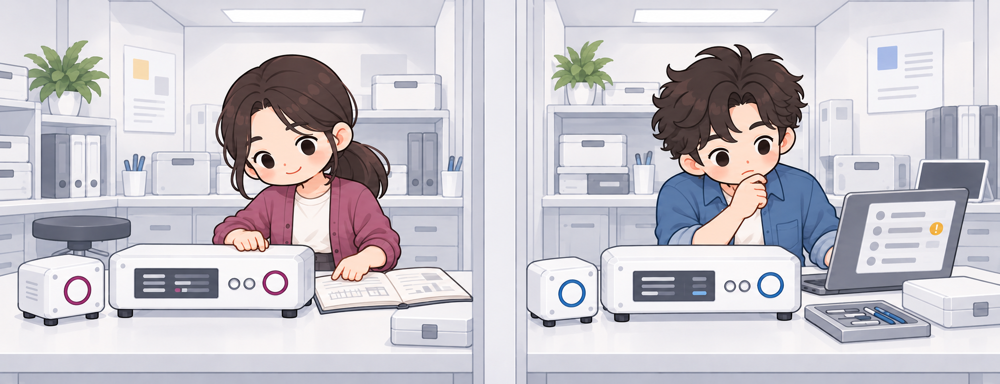


## 전송 자원과 큐비트 배치

Bell pair는 두 실험실에 배분하기 전에 준비합니다. 배분 후에는 각자의 큐비트에 대한 국소 연산과 **Alice → Bob 방향의 고전 비트 두 개**만 사용합니다.

| 전체 회로의 큐비트 | 역할 | 배분 후 위치 |
|---|---|---|
| q0 = Q | 전송할 미지 입력 | Alice |
| q1 = A | Bell pair의 한쪽 | Alice |
| q2 = B | Bell pair의 다른 쪽, 전송 후 출력 | Bob |

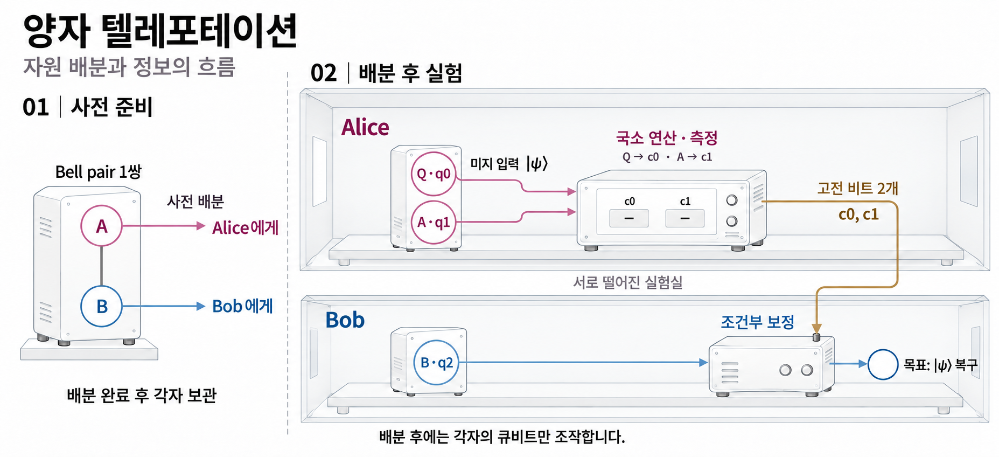

*배분 후 두 실험실 사이를 연결하는 화살표는 Alice의 측정 결과를 보내는 고전 통신입니다.*

**전체 회로의 번호와 함수 내부의 번호를 구분하세요.** 각 함수는 아래의 작은 회로를 반환하고, 제공 코드가 이를 전체 회로에 연결합니다. 예를 들어 `bob_decoder()` 안의 q0는 전체 회로의 q2에 연결됩니다.

| 함수 | 반환 회로 | 함수 내부 → 전체 회로 |
|---|---|---|
| `shared_pair()` | `QuantumCircuit(2)` | 로컬 q0=A → 전체 q1, 로컬 q1=B → 전체 q2. 초기 상태는 00 |
| `alice_encoder()` | `QuantumCircuit(2)` | 로컬 q0=Q → 전체 q0, 로컬 q1=A → 전체 q1 |
| `bob_decoder()` | `QuantumCircuit(1, 2)` | 로컬 q0=B → 전체 q2. 로컬 c0·c1에는 Alice의 결과가 연결됨 |

**Alice의 측정은 제공 코드가 추가합니다.** Q의 결과는 c0, A의 결과는 c1에 저장하므로 출력 문자열은 `c1c0` 순서입니다. 예를 들어 `10`은 c1=1, c0=0을 뜻합니다.

전송 함수에는 미지 입력의 진폭이나 입력을 준비한 회로가 제공되지 않습니다. 목표는 **모든 입력·측정 분기에서 입력 상태를 복구**하는 것입니다. 아래 준비 2 셀을 실행한 뒤 2-1부터 진행하세요.


In [ ]:
#@title 준비 2 — 전송 실험 도구
def protocol_1q(pair, alice, bob):
    """Fixed routing: q0=payload, q1=Alice resource, q2=Bob; c0,c1=Alice results."""
    validate_fragment(pair, 2)
    validate_fragment(alice, 2)
    validate_fragment(bob, 1, 2, ("h", "x", "z"), True)
    qc = QuantumCircuit(3, 2)
    qc.compose(pair, [1, 2], inplace=True)
    qc.barrier(label="resource distributed")
    qc.compose(alice, [0, 1], inplace=True)
    qc.measure([0, 1], [0, 1])
    qc.compose(bob, [2], [0, 1], inplace=True)
    return qc

def probe_states():
    states = {}
    for label, gates in [("0", []), ("1", ["x"]), ("+", ["h"]),
                         ("-", ["x", "h"]), ("+i", ["h", "s"]), ("-i", ["h", "sdg"])]:
        qc = QuantumCircuit(1)
        for gate in gates:
            getattr(qc, gate)(0)
        states[label] = qc
    return states

def haar_prep(seed, n=1):
    """Haar-random pure state in dimension 2**n, including entangled states for n=2."""
    rng = np.random.default_rng(seed)
    vector = rng.normal(size=2**n) + 1j * rng.normal(size=2**n)
    vector /= np.linalg.norm(vector)
    qc = QuantumCircuit(n)
    qc.prepare_state(vector, list(range(n)))
    return qc

def sample_fidelity(protocol, prep, inputs=(0,), outputs=(2,), shots=SHOTS, seed=SEED):
    """The referee, not the participant's protocol, prepares U|0> and verifies with U^-1."""
    if prep.num_qubits != len(inputs) or len(inputs) != len(outputs):
        raise ValueError("Input/output dimensions do not match")
    qc = QuantumCircuit(protocol.num_qubits, protocol.num_clbits)
    qc.compose(prep, list(inputs), inplace=True)
    qc.compose(protocol, inplace=True)
    verify = ClassicalRegister(len(outputs), "verify")
    qc.add_register(verify)
    qc.compose(prep.inverse(), list(outputs), inplace=True)
    qc.measure(list(outputs), verify)
    counts = BACKEND.run(compile_for_aer(qc, seed),
                         shots=shots, seed_simulator=seed).result().get_counts()
    indices = [qc.find_bit(bit).index for bit in verify]
    successes = 0
    branches = {}
    for key, count in counts.items():
        ok = all(bit_at(key, i) == 0 for i in indices)
        successes += count * ok
        label = "".join(str(bit_at(key, i)) for i in reversed(range(protocol.num_clbits)))
        good, total = branches.get(label, (0, 0))
        branches[label] = (good + count * ok, total + count)
    return {"fidelity": successes / shots,
            "branches": {k: {"shots": n, "fidelity": g/n} for k, (g, n) in sorted(branches.items())}}

def public_teleport_check(protocol, n=1, random_count=20):
    inputs, outputs = ((0,), (2,)) if n == 1 else ((0, 1), (4, 5))
    cases = probe_states() if n == 1 else {}
    cases.update({f"Haar {s}": haar_prep(s, n) for s in range(random_count)})
    scores = []
    for i, (label, prep) in enumerate(cases.items()):
        result = sample_fidelity(protocol, prep, inputs, outputs, seed=SEED+i)
        scores.append(result["fidelity"])
        if i < 6:
            print(f"{label:>8s}: F_hat={scores[-1]:.6f}")
    print(f"{len(scores)} states: mean={np.mean(scores):.6f}, min={min(scores):.6f}")
    return scores

def broken_parts():
    pair = QuantumCircuit(2)
    pair.h(0)
    pair.cx(0, 1)
    alice = QuantumCircuit(2)
    alice.cx(0, 1)
    alice.h(0)
    bob = QuantumCircuit(1, 2)
    with bob.if_test((bob.clbits[0], 1)):
        bob.x(0)
    with bob.if_test((bob.clbits[1], 1)):
        bob.z(0)
    return pair, alice, bob

def graph_pair():
    """Fixed resource: CZ|++>; CZ is expanded using H,CX,H."""
    qc = QuantumCircuit(2)
    qc.h(1)  # Bob's state BEFORE entanglement generation
    qc.h(0)
    qc.h(1)
    qc.cx(0, 1)
    qc.h(1)
    return qc

def protocol_2q(pair4, alice, bob2):
    """Resource local indices [A0,A1,B0,B1] -> global [2,3,4,5]."""
    validate_fragment(pair4, 4)
    validate_fragment(alice, 2)
    validate_fragment(bob2, 2, 4, ("h", "x", "z"), True)
    qc = QuantumCircuit(6, 4)
    qc.compose(pair4, [2, 3, 4, 5], inplace=True)
    qc.barrier(label="resource distributed")
    qc.compose(alice, [0, 2], inplace=True)
    qc.compose(alice, [1, 3], inplace=True)
    qc.measure([0, 2, 1, 3], [0, 1, 2, 3])
    qc.compose(bob2, [4, 5], [0, 1, 2, 3], inplace=True)
    return qc

def report_transfer_check(report, case, exercise):
    """Show a real failed assertion without interrupting the rest of the workbook."""
    from html import escape
    from IPython.display import HTML, display
    observed = report["fidelity"]
    message = (f"[QFF-{exercise}] 입력: {case}. "
               f"이상적 전송 검증 실패: expected F_hat=1.000000, observed F_hat={observed:.6f}.")
    try:
        assert observed == 1.0, message
    except AssertionError as error:
        display(HTML('<div style="border-left:5px solid #b44b40;background:#fff1ef;padding:14px 18px;">'
                     '<b>검증 실패 · AssertionError</b><pre style="white-space:pre-wrap;">'
                     + escape(str(error)) + '</pre>'
                     '<p>의도된 디버깅 실험입니다. 설치 오류가 아닙니다. '
                     '실패한 입력과 결과를 기록하고, 아래 회로에서 원인을 추적하세요.</p></div>'))
        return False
    print(f"[QFF-{exercise}] PASS — {case}: F_hat={observed:.6f}")
    return True

## 2-1. 오류 재현과 진단 · 6점

**먼저 바로 아래 실행 2-1 셀을 실행하여 제공된 고장 회로의 `AssertionError` 메시지를 확인하세요.** 이 실패 메시지는 의도된 디버깅 결과입니다. 여섯 입력 `0`, `1`, `+`, `-`, `+i`, `-i`와 `+` 입력의 네 측정 분기를 비교해 결함을 찾으세요. 수정 회로는 2-2에 구현합니다.

입력 라벨 `+i`와 `-i`는 각각 $|+i\rangle=(|0\rangle+i|1\rangle)/\sqrt2$, $|-i\rangle=(|0\rangle-i|1\rangle)/\sqrt2$를 뜻합니다.

아래 TODO 코드 셀에서 `teleportation_diagnosis()`를 구현하세요.

**반환 형식:** `(failed_inputs, masked_inputs, plus_branch_fidelities)`

| 반환 항목 | 내용과 순서 |
|---|---|
| `failed_inputs` | 고장 회로의 평균 fidelity가 1보다 작은 입력 라벨의 tuple |
| `masked_inputs` | 고장 회로의 평균 fidelity가 1이라 결함이 가려지는 입력 라벨의 tuple |
| `plus_branch_fidelities` | `+` 입력에서 결과 `c1 c0 = 00, 01, 10, 11`에 대응하는 조건부 fidelity 4개의 tuple |

위의 여섯 입력 라벨을 `failed_inputs`와 `masked_inputs`에 빠짐없이 한 번씩 나누어 담으세요. 두 tuple 안에서 라벨을 나열하는 순서는 자유롭습니다. 여기서 평균은 **측정 분기 확률을 반영한 평균**입니다. 조건부 fidelity는 해당 분기 상태를 정규화한 뒤 입력 상태와 비교한 값입니다. 아래 실험의 표본값을 복사하지 말고, 제공된 고장 회로로부터 정확한 값을 계산하세요.

**채점 사항:** 여섯 입력의 분류와 네 분기의 수치 결과.


In [ ]:
with _qff_experiment("제공 실험 38"):
    #@title 실행 2-1 — 먼저 눌러 고장 재현 — 오류 메시지에서 출발
    # 먼저 ▶를 누르세요. 이 셀은 실패 증상을 재현하는 제공 코드입니다.
    # 원인을 찾은 뒤, 수정한 세 회로는 2-2의 '직접 작성' 셀에 구현합니다.
    pair_bad = QuantumCircuit(2)
    pair_bad.h(0)
    pair_bad.cx(0, 1)
    
    alice_bad = QuantumCircuit(2)
    alice_bad.cx(0, 1)
    alice_bad.h(0)
    
    bob_bad = QuantumCircuit(1, 2)
    with bob_bad.if_test((bob_bad.clbits[0], 1)):
        bob_bad.x(0)
    with bob_bad.if_test((bob_bad.clbits[1], 1)):
        bob_bad.z(0)
    
    broken = protocol_1q(pair_bad, alice_bad, bob_bad)
    debug_report_2_1 = sample_fidelity(broken, probe_states()["+"])
    debug_passed_2_1 = report_transfer_check(debug_report_2_1, "|+>", "2-1")
    display(broken.draw("mpl", fold=100, cregbundle=False))
    print("추가 단서: 여섯 입력을 같은 회로에 보낸 결과")
    for label, prep in probe_states().items():
        print(label, sample_fidelity(broken, prep)["fidelity"])
    print("|+> branch report (c1 c0):")
    show_fidelity(debug_report_2_1)


In [ ]:
# 직접 작성 2-1 — TODO BEGIN과 TODO END 사이만 작성하세요.
def teleportation_diagnosis():
    failed_inputs = masked_inputs = plus_branch_fidelities = None
    # TODO BEGIN — 아래 raise를 지우고 필요한 계산/연산을 작성하세요.
    raise NotImplementedError("teleportation_diagnosis")
    # TODO END
    return failed_inputs, masked_inputs, plus_branch_fidelities


**실험 메모 2-1 · 채점 제외**

- 실패 메시지와 여섯 입력의 결과를 비교하세요. 어떤 입력에서 결함이 드러나고, 어떤 입력에서는 가려지나요?
- `+` 입력의 네 측정 분기에서 구한 fidelity를 근거로, 고장 회로의 결함을 설명하세요.

관찰·계산·해석:

…


## 2-2. 전송 회로 복구 · 18점

`shared_pair()`, `alice_encoder()`, `bob_decoder()`를 완성해 **모든 입력·측정 분기에서 $F=1$**인 전송을 구현하세요. 각 함수가 반환하는 회로의 큐비트·고전 비트 수와 로컬 인덱스는 위 「전송 자원과 큐비트 배치」 표를 따릅니다.

- `shared_pair()`는 00에서 $|\Phi^+\rangle$를 준비합니다.
- `alice_encoder()`는 로컬 `[Q, A]`의 측정 전 연산을 반환합니다.
- `bob_decoder()`는 `QuantumCircuit(1, 2)`를 반환합니다. q0는 Bob, c0·c1은 Alice의 측정 결과이며, H/X/Z와 `if_test`를 사용합니다.

`if_test`는 `with qc.if_test((qc.clbits[i], 1)):`처럼 **이 회로의 고전 비트 하나를 0 또는 1과 비교**하는 조건으로 작성하세요. 여러 비트의 조건이 필요하면 `if_test`를 중첩할 수 있습니다. `qc.cregs[0]` 같은 고전 레지스터 전체를 정수와 비교하거나, 고전 논리식을 조건으로 사용하는 방식은 허용하지 않습니다. 이 제한은 2-4(b)와 선택 2-5의 Bob 보정에도 동일하게 적용됩니다.

아래 「실행 2-2 — 수정 후 재검증 — 복구 회로와 전송 fidelity」 셀은 세 회로를 연결하고 Alice의 측정을 추가하여, Bob의 보정 후 전송 fidelity를 표본으로 추정합니다. 이 출력으로 복구 결과를 확인하세요.

**채점 사항:** Bell 자원 준비와 전체 전송 채널. 임의의 미지 입력을 모든 측정 분기에서 복구하는지 확인하며, 같은 동작을 하는 다른 회로·보정 순서도 허용합니다.


In [ ]:
# 직접 작성 2-2 — TODO BEGIN과 TODO END 사이만 작성하세요.
def shared_pair():
    "00에서 Phi+를 준비하는 2-qubit 회로"
    qc = QuantumCircuit(2)
    # TODO BEGIN — 아래 raise를 지우고 필요한 계산/연산을 작성하세요.
    raise NotImplementedError("shared_pair")
    # TODO END
    return qc


In [ ]:
# 직접 작성 2-2 — TODO BEGIN과 TODO END 사이만 작성하세요.
def alice_encoder():
    "Q,A 순서의 2-qubit 회로. 측정은 넣지 마세요."
    qc = QuantumCircuit(2)
    # TODO BEGIN — 아래 raise를 지우고 필요한 계산/연산을 작성하세요.
    raise NotImplementedError("alice_encoder")
    # TODO END
    return qc


In [ ]:
# 직접 작성 2-2 — TODO BEGIN과 TODO END 사이만 작성하세요.
def bob_decoder():
    "QuantumCircuit(1, 2), q0=Bob, c0/c1=Alice 결과"
    qc = QuantumCircuit(1, 2)
    # TODO BEGIN — 아래 raise를 지우고 필요한 계산/연산을 작성하세요.
    raise NotImplementedError("bob_decoder")
    # TODO END
    return qc


In [ ]:
#@title 실행 2-2 — 수정 후 재검증 — 복구 회로와 전송 fidelity
def inspect_fixed():
    protocol = protocol_1q(shared_pair(), alice_encoder(), bob_decoder())
    display(protocol.draw("mpl", fold=100, cregbundle=False))
    return public_teleport_check(protocol)

fixed_results = run_if_ready(inspect_fixed)

**실험 메모 2-2 · 채점 제외**

- 각 측정 결과 `c1c0 = 00, 01, 10, 11`에 대한 Bob의 보정 전 상태를 계산하고, 적용한 보정 연산과 함께 정리하세요.
- X·Z 보정 순서를 바꾸면 어떤 차이가 생기나요? 복구 회로의 검증 결과와 함께 설명하세요.

관찰·계산·해석:

…


## 2-3. 전송 검증의 의미 · 7점

2-2의 실행 결과에는 여섯 기준 상태와 Haar 무작위 순수 상태 20개에 대한 fidelity 추정값이 표시됩니다. 이 결과를 확인한 뒤, `teleportation_validation()`에서 **보정 후 전송 성능**과 **보정 전 Bob의 평균 상태**를 구분해 계산하세요.

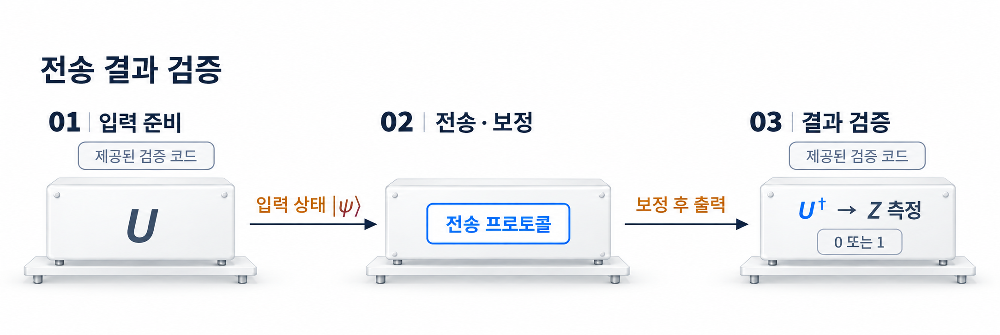

제공 검증 코드는 입력을 준비한 $U$를 알고 있으므로, Bob의 보정 후 출력에 $U^\dagger$를 적용한 뒤 Z 측정합니다. **0이 측정될 확률은 원래 입력 상태에 대한 fidelity**입니다. 전송 프로토콜에는 $U$의 준비 정보가 전달되지 않습니다.

**반환 형식:** `(mean_F, min_F, bob_average_density)`

| 반환 항목 | 계산 대상 |
|---|---|
| `mean_F` | `probe_states()`의 여섯 상태와 `haar_prep(seed)`의 `seed=0, …, 19`에 대한 보정 후 이상적 fidelity 26개의 산술평균 |
| `min_F` | 같은 26개 fidelity의 최솟값 |
| `bob_average_density` | 정상적인 전송에서 Alice의 결과를 받기 전, 측정 분기 확률로 평균한 Bob의 2×2 밀도행렬. 기준 입력은 `0` |

**① 보정 후 fidelity: `mean_F`, `min_F`**

2-2에서 복구한 회로를 사용합니다. 각 입력 $|\psi\rangle$에 대해 Alice의 측정 분기별로 **Bob의 보정을 적용한 뒤** Bob의 밀도행렬을 구하고, 분기 확률로 가중 평균하여 $\rho_B$를 계산하세요. 해당 입력의 fidelity는 $F=\langle\psi|\rho_B|\psi\rangle$입니다. 26개 입력의 결과로 평균과 최솟값을 구합니다.

**② 보정 전 평균 상태: `bob_average_density`**

이 항목은 **정상적인 전송 회로**를 기준으로 계산합니다. 입력 `0`에 대해 **Bob의 보정을 적용하기 전** 각 측정 분기의 Bob 밀도행렬을 구하고, 분기 확률로 가중 평균하세요. 행·열 순서는 `0, 1`입니다. NumPy 배열 또는 중첩 수열로 반환하며, 복소수 자료형을 유지하거나 수치 오차 수준의 허수부를 제거해도 됩니다. 정상적인 전송에서는 미지 입력을 바꾸어도 이 평균 상태가 같아야 합니다.

**정확한 값과 표본 추정값을 구분하세요.** 실행 화면에는 반복 측정으로 얻은 fidelity 추정값이 표시됩니다. 이 문항의 반환값에는 4096-shot 표본값을 사용하지 않고 정확한 확률·밀도행렬에서 계산한 값을 사용합니다.

**채점 사항:** `mean_F`·`min_F`는 2-2의 회로가 모든 입력·측정 분기에서 전송 조건을 만족하는 경우에 채점합니다. `bob_average_density`는 정상적인 전송의 이론적 평균 상태를 기준으로 **2-2 통과 여부와 독립적으로 채점**합니다. 2-2가 미완성이어도 이 평균 상태를 계산해 제출할 수 있으며, 작성 중인 오답 회로의 평균 상태를 반환하는 항목은 아닙니다.


In [ ]:
# 직접 작성 2-3 — TODO BEGIN과 TODO END 사이만 작성하세요.
def teleportation_validation():
    mean_F = min_F = bob_average_density = None
    # TODO BEGIN — 아래 raise를 지우고 필요한 계산/연산을 작성하세요.
    raise NotImplementedError("teleportation_validation")
    # TODO END
    return mean_F, min_F, bob_average_density


**실험 메모 2-3 · 채점 제외**

- $U|0\rangle=|\psi\rangle$일 때, 보정 후 Bob 출력에 $U^\dagger$를 적용하여 얻는 $P(0)$가 왜 $\langle\psi|\rho_B|\psi\rangle$와 같을까요? 입력을 모르는 Bob도 이 검증을 직접 할 수 있을까요?
- 이상적인 전송에서 유한한 측정 횟수로 얻은 fidelity 추정값이 정확히 1이 될 수 있을까요?
- Alice의 고전 결과가 전달되기 전에, Alice가 입력 상태를 달리 준비하는 것만으로 Bob에게 정보를 보낼 수 없는 이유를 설명하세요.

관찰·계산·해석:

…


## 2-4. 교체 자원에 맞춰 장치 조정 · 9점

**(a) 초기 상태가 달라졌을 때의 Bell pair 준비**

얽힘 생성 전 초기 상태는 $|0\rangle_A|+\rangle_B$입니다. 아래 「실행 2-4 — 자원 비교 — 준비 방식 확인」 셀에서 이 초기 상태에 H(A)와 CX(A,B)를 차례로 적용한 결과를 관찰하고, 얽힘이 만들어지는지 확인하세요. 이어 같은 초기 상태를 $|\Phi^+\rangle$로 바꾸는 변환 회로를 `bell_pair_from_b_plus()`에 구현하세요.

반환값은 **초기 상태 뒤에 붙일 변환 전체를 담은** 측정 없는 `QuantumCircuit(2)`입니다. 로컬 q0=A, q1=B이며 H/X/Z/CX를 사용할 수 있습니다. 변환 안에서 게이트를 적용하는 순서는 직접 결정하세요. 초기 B의 `+` 준비는 채점 코드가 먼저 적용합니다. 목표 상태는 $|\Phi^+\rangle$입니다.

**실행 셀의 확인 범위:** 「실행 2-4 — 자원 비교 — 준비 방식 확인」은 제공된 고정 회로를 비교하며, `bell_pair_from_b_plus()`를 호출하지 않습니다. 뒤의 「실행 2-4 — 보정 확인 — graph 자원 전송」도 (b)의 전송만 확인합니다. 두 실행 셀이 정상 출력되어도 (a)의 답안이 검증된 것은 아닙니다. **`bell_pair_from_b_plus()`의 반환 회로는 마지막 채점 셀에서 검사합니다.**

**(b) Graph 자원의 보정**

고정 자원 $|G\rangle=CZ|++\rangle=(I_A\otimes H_B)|\Phi^+\rangle$에 맞는 `bob_graph_decoder()`를 작성하세요. `graph_pair()`와 **2-2에서 작성한 Alice 연산**을 그대로 사용합니다. `bob_graph_decoder()`도 `bob_decoder()`와 마찬가지로 `QuantumCircuit(1, 2)`를 반환하며, H/X/Z와 `if_test`만 사용할 수 있습니다. `if_test`에는 2-2와 같은 단일 로컬 고전 비트의 0/1 조건만 사용하세요. 위 텐서 표기는 A,B 순서입니다.

**채점 사항:** (a)의 Bell 준비와 (b)의 모든 입력·측정 분기 전송.


In [ ]:
# 직접 작성 2-4 — TODO BEGIN과 TODO END 사이만 작성하세요.
def bell_pair_from_b_plus():
    qc = QuantumCircuit(2)
    # TODO BEGIN — 아래 raise를 지우고 필요한 계산/연산을 작성하세요.
    raise NotImplementedError("bell_pair_from_b_plus")
    # TODO END
    return qc


In [ ]:
with _qff_experiment("제공 실험 49"):
    #@title 실행 2-4 — 자원 비교 — 준비 방식 확인
    plus_attempt = QuantumCircuit(2)
    plus_attempt.h(1)
    plus_attempt.h(0)
    plus_attempt.cx(0, 1)
    print("CX attempt, Bob purity:", partial_trace(Statevector(plus_attempt), [0]).purity().real)
    print("Graph resource, Bob purity:", partial_trace(Statevector(graph_pair()), [0]).purity().real)
    display(graph_pair().draw("mpl"))


In [ ]:
# 직접 작성 2-4 — TODO BEGIN과 TODO END 사이만 작성하세요.
def bob_graph_decoder():
    "고정 graph 자원용 QuantumCircuit(1, 2). H,X,Z와 if_test 허용"
    qc = QuantumCircuit(1, 2)
    # TODO BEGIN — 아래 raise를 지우고 필요한 계산/연산을 작성하세요.
    raise NotImplementedError("bob_graph_decoder")
    # TODO END
    return qc


In [ ]:
#@title 실행 2-4 — 보정 확인 — graph 자원 전송
def inspect_graph():
    protocol = protocol_1q(graph_pair(), alice_encoder(), bob_graph_decoder())
    display(protocol.draw("mpl", fold=100, cregbundle=False))
    return public_teleport_check(protocol)

graph_results = run_if_ready(inspect_graph)

**실험 메모 2-4 · 채점 제외**

- 초기 상태가 $|0\rangle_A|+\rangle_B$일 때 H(A)와 CX(A,B)를 차례로 적용한 회로가 얽힘을 준비하는지 설명하세요. 여러분의 Bell 준비 회로와 비교하세요.
- Graph 자원으로 바꾸었을 때 Bob의 보정을 어떻게 조정했나요? 필요한 보정과 적용 순서를 설명하세요.

관찰·계산·해석:

…


## 연결 실험 — GHZ의 한 몫을 전달하라

**새 TODO를 작성하지 않고 1-6과 2-2의 답안 함수를 연결하는 제공 실험입니다.** 복구한 장치가 얽힘도 보존하는지 확인합니다. Alice는 GHZ 상태를 이루는 큐비트 중 q0와 q3를 가지고, Charlie는 q4를 가집니다. 이때 q0가 맡고 있는 양자 정보를 Bob의 q2로 전송하면서 q3·q4와의 얽힘을 보존해야 합니다. 전송에 사용하는 Bell pair는 Alice의 q1과 Bob의 q2가 공유합니다.
아래 「연결 실험 — 복구한 회로로 GHZ의 한 몫 전송」 셀은 **1-6의 준비 함수와 2-2의 전송 함수**를 재사용합니다. 출력되는 두 값을 구분해 확인하세요.

- **입력 GHZ 준비 fidelity:** 1-6에서 준비한 입력 상태와 목표 GHZ 상태를 비교합니다.
- **전송 fidelity:** 전송 후 Alice(q3)·Bob(q2)·Charlie(q4)의 상태를, 여러분이 실제로 준비했던 입력 상태와 비교합니다. 세 큐비트의 전체 상태가 얼마나 잘 보존되었는지를 표본 측정으로 추정한 값입니다.

GHZ 준비와 전송이 모두 올바른지 두 검증을 함께 확인하세요. 전송 후 세 실험실이 나누어 가진 이 자원은 3부의 연결 실험에서도 사용합니다.

**검증할 대상은 세 큐비트의 전체 상태입니다.** GHZ의 q0만 따로 보면 순수한 단일 큐비트 상태가 아닙니다. 따라서 각 큐비트의 측정 결과만으로 전송 성공을 판단하지 않고, 다른 큐비트와의 상관관계까지 확인합니다.


In [ ]:
#@title 연결 실험 — 복구한 회로로 GHZ의 한 몫 전송
# 제공 코드: 새 함수를 작성하지 않고 1-6과 2-2의 결과를 연결합니다.
def linked_ghz_setup():
    prep = validate_fragment(build_ghz_state(), 3)
    transfer = protocol_1q(shared_pair(), alice_encoder(), bob_decoder())
    protocol = QuantumCircuit(5, 2)
    protocol.compose(transfer, [0, 1, 2], [0, 1], inplace=True)
    return prep, protocol

def inspect_linked_ghz():
    prep, protocol = linked_ghz_setup()
    report = sample_fidelity(protocol, prep, inputs=(0, 3, 4), outputs=(2, 3, 4))
    target = Statevector(np.array([1,0,0,0,0,0,0,1])/np.sqrt(2))
    print("입력 GHZ 준비 fidelity:", state_fidelity(Statevector(prep), target))
    print("준비한 세 qubit 전체의 전송 fidelity (c1 c0의 모든 분기 포함)")
    show_fidelity(report)
    return report

linked_ghz_result = run_if_ready(inspect_linked_ghz)


**전송 시험 완료 기준:** Alice의 측정 결과에 따라 Bob의 상태를 보정하여 입력 상태를 복구하고, 입력이 다른 큐비트와 맺고 있던 얽힘도 보존해야 합니다. 이제 세 실험실이 입력 이후 통신 없이 이 공유 자원을 활용하는지 시험합니다.


<a id="part3"></a>

# 3. GHZ–Mermin 게임 — 협력 시험

이번에는 세 실험실이 **자기에게 주어진 입력만 보고 공동 조건을 만족하는 응답**을 만들어야 합니다. 입력을 받은 뒤에는 서로 통신할 수 없습니다. 사전에 정한 고전 전략과 GHZ를 이용한 양자 전략의 평균 승률을 비교하세요.

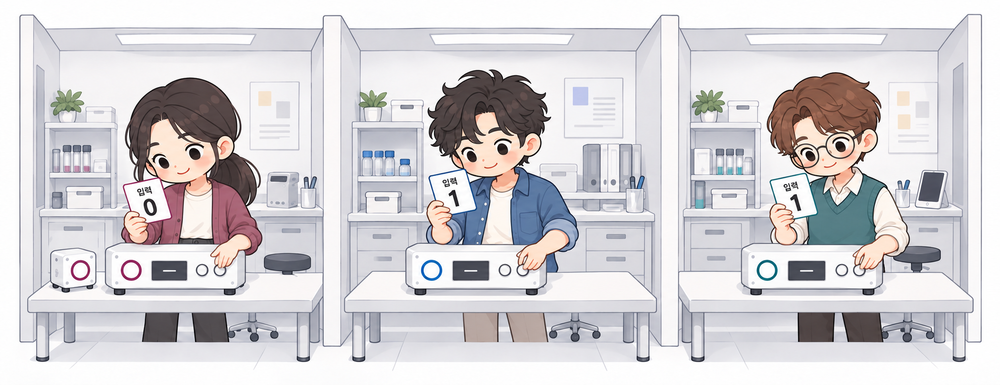

*허용 입력 중 011이 선택된 한 라운드의 예시입니다. Alice는 0, Bob은 1, Charlie는 1만 확인합니다. 각자는 다른 실험실의 입력을 볼 수 없습니다.*

한 라운드의 승리 점수와 이 문제지의 문항 배점은 별개입니다. 게임에서 세 사람의 공동 응답이 조건을 만족하면 팀 전체가 1점을 얻습니다.


## 게임 규칙 — 준비, 입력, 응답, 판정

**입력 $x,y,z$는 심판이 각 실험실에 보내는 고전 비트**이며, 큐비트의 초기 상태나 측정 결과가 아닙니다. Alice는 $x$, Bob은 $y$, Charlie는 $z$를 받고, 각각 출력 비트 $a,b,c$를 냅니다.

1. **사전 준비:** 각자는 자기 입력이 0일 때와 1일 때의 행동을 미리 정합니다. 사전 합의와 공유 난수는 허용합니다. 양자 전략에서는 이 단계에 GHZ를 준비해 한 큐비트씩 배분합니다.
2. **입력 배분:** 심판이 `xyz = 000, 011, 101, 110` 중 하나를 **각각 확률 1/4**로 선택합니다. 이 선택은 사전 공유 자원과 독립적입니다. 각자는 자기 입력 하나만 받습니다.
3. **각자의 응답:** 입력을 받은 뒤에는 통신하지 않습니다. 고전 전략은 미리 정한 출력 규칙을, 양자 전략은 자기 입력에 맞춘 국소 측정을 사용합니다.
4. **공동 판정:** 세 사람의 응답이 끝나면 심판이 $a,b,c$를 모아 아래 조건으로 승패를 판정합니다. 성공하면 팀 전체가 1점, 실패하면 0점입니다.

| 입력 `xyz` | 승리하려면 출력 `abc`에 포함되어야 하는 1의 개수 | 출력 parity |
|---|---|---|
| `000` | 0개 또는 2개 — 짝수 | 0 |
| `011`, `101`, `110` | 1개 또는 3개 — 홀수 | 1 |

예를 들어 입력이 `011`이고 응답 `abc`가 `001`이면 1이 한 개이므로 승리합니다. 같은 입력에서 `abc=000`이면 패배합니다. 이것은 한 라운드의 판정 예시이며, 전략은 모든 허용 입력에 대응할 수 있도록 사전에 정합니다.

이 조건을 식으로 쓰면 다음과 같습니다. $\oplus$는 비트의 배타적 논리합(XOR)입니다.

$$a\oplus b\oplus c=\frac{x+y+z}{2}\pmod2.$$

평균 승률은 네 허용 입력에 대한 승률을 균등하게 평균한 값입니다. 제공 게임 실험은 **각 입력을 4096회씩** 측정하므로, 입력별 표본 승률 네 개의 평균은 전체 성공 횟수를 전체 시행 횟수로 나눈 값과 같습니다. 양자 실험은 매 라운드 새로 준비한 공유 자원을 사용합니다.

**큐비트 배정:** 직접 준비한 GHZ에서는 Alice·Bob·Charlie가 각각 q0·q1·q2를 사용합니다. 2부와의 연결 실험에서는 같은 순서로 q3·q2·q4를 사용합니다. 국소 측정값 +1은 출력 비트 0, −1은 출력 비트 1에 대응합니다.

아래 준비 3 셀을 실행한 뒤 고전 전략부터 조사하세요.


In [ ]:
#@title 준비 3 — 게임 실험 도구
INPUTS = ((0,0,0), (0,1,1), (1,0,1), (1,1,0))
PARTIES = ("Alice", "Bob", "Charlie")

def winning_parity(x, y, z):
    if (x, y, z) not in INPUTS:
        raise ValueError("Only promised input triples are used")
    return ((x + y + z) // 2) % 2

def freeze_strategy(local_basis):
    """Build six local circuits once, BEFORE the referee selects any input triple."""
    table = {}
    for party in PARTIES:
        for bit in (0, 1):
            table[party, bit] = validate_fragment(
                local_basis(party, bit), 1, allowed=("h", "s", "sdg", "x", "z")).copy()
    return table

def game_unitary(resource, strategy, xyz):
    validate_fragment(resource, resource.num_qubits)
    if resource.num_qubits not in (3, 4):
        raise ValueError("Expected 3 players, with optional inaccessible q3")
    if xyz not in INPUTS:
        raise ValueError("Invalid input triple")
    qc = resource.copy()
    qc.barrier(label="inputs distributed")
    for q, (party, bit) in enumerate(zip(PARTIES, xyz)):
        fragment = validate_fragment(strategy[party, bit], 1,
                                     allowed=("h", "s", "sdg", "x", "z"))
        qc.compose(fragment, [q], inplace=True)
    return qc

def build_mermin_round(resource, strategy, xyz):
    qc = game_unitary(resource, strategy, xyz)
    out = ClassicalRegister(3, "out")
    qc.add_register(out)
    qc.measure([0, 1, 2], out)
    return qc

def sample_game(resource, strategy, shots=SHOTS, seed=SEED):
    rows = []
    circuits = [build_mermin_round(resource, strategy, xyz) for xyz in INPUTS]
    result = BACKEND.run(compile_for_aer(circuits, seed),
                         shots=shots, seed_simulator=seed).result()
    for i, xyz in enumerate(INPUTS):
        counts = result.get_counts(i)
        wins = sum(n for key, n in counts.items()
                   if sum(map(int, key.replace(" ", ""))) % 2 == winning_parity(*xyz))
        ev = sum((-1)**sum(map(int, key.replace(" ", ""))) * n for key, n in counts.items())/shots
        rows.append({"input": xyz, "win_rate": wins/shots, "correlator": ev})
    # This is the game Bell expression for the submitted observables.
    m = rows[0]["correlator"] - sum(row["correlator"] for row in rows[1:])
    return {"rows": rows, "p_win": np.mean([r["win_rate"] for r in rows]), "M": m}

def exact_game(resource, strategy):
    rows = []
    for xyz in INPUTS:
        probabilities = Statevector.from_instruction(game_unitary(resource, strategy, xyz)).probabilities([0, 1, 2])
        ev = sum((-1)**i.bit_count()*p for i, p in enumerate(probabilities))
        rows.append({"input": xyz, "win_rate": (1+(-1)**winning_parity(*xyz)*ev)/2, "correlator": ev})
    m = rows[0]["correlator"] - sum(row["correlator"] for row in rows[1:])
    return {"rows": rows, "p_win": np.mean([r["win_rate"] for r in rows]), "M": m}

def coin_resource():
    """q3 purifies the mixture and is inaccessible to all three players."""
    qc = QuantumCircuit(4)
    qc.h(3)
    for q in (0, 1, 2):
        qc.cx(3, q)
    return qc

def sample_linked_game(strategy, shots=SHOTS, seed=SEED):
    """Use all teleportation branches; only final game bits determine the score."""
    prep, protocol = linked_ghz_setup()
    circuits = []
    for xyz in INPUTS:
        qc = QuantumCircuit(5, 2)
        qc.compose(prep, [0, 3, 4], inplace=True)
        qc.compose(protocol, inplace=True)
        qc.barrier(label="inputs distributed")  # Transfer/corrections are already complete.
        for q, party, bit in zip((3, 2, 4), PARTIES, xyz):  # Alice, Bob, Charlie
            qc.compose(validate_fragment(strategy[party, bit], 1,
                       allowed=("h", "s", "sdg", "x", "z")), [q], inplace=True)
        out = ClassicalRegister(3, "out")
        qc.add_register(out)
        qc.measure([3, 2, 4], out)
        circuits.append(qc)
    result = BACKEND.run(compile_for_aer(circuits, seed), shots=shots,
                         seed_simulator=seed).result()
    rows = []
    for i, xyz in enumerate(INPUTS):
        counts = result.get_counts(i)
        wins, signed = 0, 0
        for key, count in counts.items():
            parity = sum(bit_at(key, j) for j in (2, 3, 4)) % 2
            wins += count * (parity == winning_parity(*xyz))
            signed += count * (-1)**parity
        rows.append({"input": xyz, "win_rate": wins/shots, "correlator": signed/shots})
    m = rows[0]["correlator"] - sum(row["correlator"] for row in rows[1:])
    return {"rows": rows, "p_win": np.mean([row["win_rate"] for row in rows]), "M": m}


## 3-1. 고전 전략의 한계 · 7점

한 사람의 전략을 `(입력0의 출력, 입력1의 출력)`으로 나타냅니다. `classical_search()`에서 세 사람의 **64개 결정론적 전략 조합을 조사**하고 `(최대 승률, (sa, sb, sc))`를 반환하세요. 각 전략은 입력이 0일 때와 1일 때 출력할 비트를 순서대로 담은 쌍입니다. `sa`, `sb`, `sc`는 각각 Alice, Bob, Charlie의 전략입니다. 승률은 네 허용 입력이 같은 확률로 주어질 때의 평균 승률입니다.

양자 전략의 성능과 비교할 기준으로, 가장 좋은 고전 전략을 구합니다.

**채점 사항:** 반환한 최대 승률, 해당 승률을 실제로 달성하는 전략, 두 결과의 일치. 같은 최댓값을 달성하는 다른 전략도 허용합니다.


In [ ]:
# 직접 작성 3-1 — TODO BEGIN과 TODO END 사이만 작성하세요.
def classical_search():
    "64가지 조합을 확인하고 (best_probability, (sa,sb,sc)) 반환"
    best_probability = None
    sa = sb = sc = None
    # TODO BEGIN — 아래 raise를 지우고 필요한 계산/연산을 작성하세요.
    raise NotImplementedError("classical_search")
    # TODO END
    return best_probability, (sa, sb, sc)


In [ ]:
#@title 실행 3-1 — 고전 전략의 최대 승률 확인
classical_result = run_if_ready(classical_search)
print("classical result:", classical_result)

**실험 메모 3-1 · 채점 제외**

- 찾은 최적 고전 전략의 예를 쓰고, 네 허용 입력에서 언제 성공하고 실패하는지 확인하세요.
- 모든 입력에서 성공할 수 없는 이유를 parity로 설명하고, 공유 난수를 사용해도 고전 상한을 높일 수 없는 이유를 정리하세요.

관찰·계산·해석:

…


## 3-2. GHZ 측정 전략 · 10점

`build_ghz3()`로 GHZ+를 준비하고, 아래 성질을 이용해 `local_basis(party, input_bit)`를 설계하세요.

$$\langle XXX\rangle=+1,\qquad \langle XYY\rangle=\langle YXY\rangle=\langle YYX\rangle=-1.$$

`build_ghz3()`는 **H/X/Z/CX만 사용한** 측정 없는 `QuantumCircuit(3)`을 반환합니다. S/S†의 추가 허용은 아래 `local_basis()`에만 적용됩니다. `local_basis()`는 `party`가 `"Alice"`, `"Bob"`, `"Charlie"` 중 하나이고 `input_bit`가 0 또는 1일 때, H/X/Z/S/S†로 만든 측정 없는 `QuantumCircuit(1)`을 반환합니다. 각 참가자의 회로는 그 참가자의 이름과 입력 비트만으로 정해야 합니다. 세 참가자 각각에 대해 입력이 0일 때와 1일 때 사용할 회로, 총 여섯 개를 게임의 입력 조합이 선택되기 전에 미리 정해 두세요.

`local_basis()`에는 원하는 측정을 구현하기 위한 **측정 전 기저 변환 게이트만** 작성하세요. 제공 실험 코드가 이 회로 뒤에 Z 기저 측정을 추가하고, 측정 결과 0/1을 각자의 출력 비트로 사용합니다.

**힌트:** X 측정은 H 후 Z 측정, Y 측정은 S† → H 후 Z 측정으로 구현합니다.

**채점 사항:** GHZ+ 준비와 네 입력에서의 공동 성공 조건. GHZ+ 준비와 함께 입력에 맞는 측정 전 기저 변환을 구현해야 합니다.

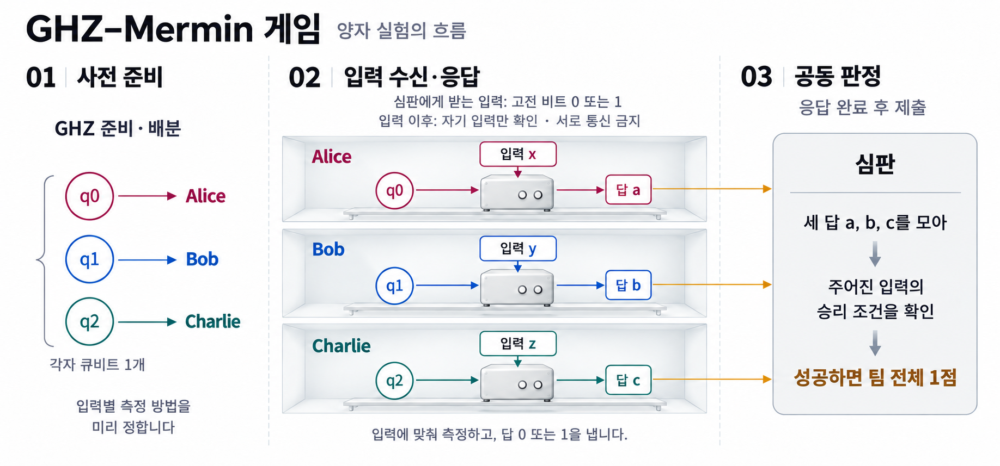

*양자 전략의 한 라운드입니다. GHZ 준비와 입력별 측정법 결정은 입력 배분 전에 마치며, 세 응답은 모두 끝난 뒤 공동 판정에 사용합니다.*


In [ ]:
# 직접 작성 3-2 — TODO BEGIN과 TODO END 사이만 작성하세요.
def build_ghz3():
    "000에서 GHZ+를 만드는 3-qubit 회로. 측정은 넣지 마세요."
    qc = QuantumCircuit(3)
    # TODO BEGIN — 아래 raise를 지우고 필요한 계산/연산을 작성하세요.
    raise NotImplementedError("build_ghz3")
    # TODO END
    return qc


In [ ]:
# 직접 작성 3-2 — TODO BEGIN과 TODO END 사이만 작성하세요.
def local_basis(party, input_bit):
    "자신의 party·입력만 사용하는 1-qubit basis 변환"
    qc = QuantumCircuit(1)
    # TODO BEGIN — 아래 raise를 지우고 필요한 계산/연산을 작성하세요.
    raise NotImplementedError("local_basis")
    # TODO END
    return qc


In [ ]:
#@title 실행 3-2 — GHZ 준비와 로컬 측정 확인
def inspect_strategy():
    resource = validate_fragment(build_ghz3(), 3)
    target = Statevector(np.array([1,0,0,0,0,0,0,1])/np.sqrt(2))
    print("GHZ preparation fidelity:", state_fidelity(Statevector(resource), target))
    strategy = freeze_strategy(local_basis)
    display(resource.draw("mpl"))
    for party in PARTIES:
        for bit in (0, 1):
            print(f"{party} input: {bit}")
            display(strategy[party, bit].draw("mpl"))
    display(build_mermin_round(resource, strategy, (0, 1, 1)).draw("mpl", fold=100))

run_if_ready(inspect_strategy)

**실험 메모 3-2 · 채점 제외**

- 각 참가자가 입력 0과 1에 대해 선택한 측정 관측량(observable)과, 이를 구현하는 게이트의 시간 순서를 정리하세요.
- 선택한 측정과 GHZ의 상관관계가 네 허용 입력의 공동 성공 조건을 어떻게 만족시키는지 설명하세요.

관찰·계산·해석:

…


## 게임 결과 문자열 읽기

입력은 `xyz`, 사람 순서의 응답은 `abc`로 씁니다. Qiskit이 표시하는 게임 측정 결과는 높은 인덱스부터 나열하므로 **`cba` 순서**입니다.

| 실험 | 원시 counts 키 | 승률·parity에 사용할 부분 |
|---|---|---|
| 직접 준비한 GHZ | `cba` | 게임 출력 세 비트 모두 |
| 2부와의 연결 실험 | `cba c1c0` | 앞의 게임 출력 세 비트 `cba`만 |

연결 실험의 뒤쪽 `c1c0`는 Alice의 텔레포테이션 측정 결과이며 게임 응답이 아닙니다. 제공 게임 도구는 텔레포테이션의 모든 측정 분기를 포함하고, 게임 출력 세 비트만으로 parity와 승률을 계산합니다. GHZ 준비 fidelity와 게임 승률도 서로 다른 확인 항목입니다.


## 3-3. 승률과 Mermin 값 · 7점

`mermin_report()`에서는 네 입력 각각에 대한 상관값(correlator) $E_{xyz}=\langle(-1)^{a+b+c}\rangle$와 승률을 **정확한 확률로 계산하여 반환**하세요. 아래 제공 실험은 입력마다 4096회 측정한 표본 결과와 정확한 계산 결과를 함께 출력합니다. 두 결과를 비교하세요.

$$M_{game}=E_{000}-E_{011}-E_{101}-E_{110}.$$

아래 TODO 코드 셀에서 `mermin_report()`를 작성합니다. **3-2에서 작성한 GHZ 준비 회로와 여섯 측정 전 기저 변환 회로**를 사용하세요.

**반환 형식:** `(E, win_rates, M, p_win)`

- `E`: 입력 `000, 011, 101, 110` 순서의 정확한 상관값 4개.
- `win_rates`: 같은 입력 순서의 정확한 승률 4개.
- `M`: 위 식으로 계산한 Mermin 게임 값.
- `p_win`: 네 입력을 균등하게 평균한 승률.

`E`와 `win_rates`는 각각 길이 4의 tuple로 반환합니다. 확률 계산은 자유롭게 구현할 수 있으며, 공개된 정확 계산 도구를 활용해도 됩니다.

**채점 사항:** 네 입력의 수치 결과와 전체 M·승률. 이 수치 항목은 **3-2의 GHZ+ 준비와 측정 전략이 요구 조건을 만족하는 경우에 채점**합니다.

| 평균 승률 | M 값 | 의미 |
|---|---:|---|
| 75% | 2 | 가장 좋은 고전 전략의 평균 성능 |
| 75% 초과 | 2 초과 | 공유 난수와 사전 합의만으로 가능한 평균 성능을 넘어섬 |
| 100% | 4 | 모든 허용 입력에서 공동 조건을 만족함 |

표의 고전 상한 75%는 네 입력이 같은 확률로 주어질 때의 이론적 평균 승률에 적용됩니다. 유한한 횟수로 실험해 얻은 승률은 표본 변동 때문에 75%를 넘을 수도 있습니다.

아래 「실행 3-3 — 네 입력의 승률·M 확인」 셀은 직접 준비한 GHZ의 정확한 계산 결과·표본 결과와, **2부에서 전송한 GHZ의 표본 결과**를 함께 보여 줍니다. 2부가 미완성이어도 직접 준비한 GHZ 시험은 진행할 수 있습니다. `mermin_report()`의 계산 대상은 직접 준비한 3-2의 자원입니다.

이 실행 셀은 비교용 결과를 별도로 계산하며 **`mermin_report()`를 호출하지 않습니다.** 따라서 실험 결과가 출력되어도 해당 TODO 함수의 완성 여부나 반환값이 검증된 것은 아닙니다. 이 함수의 반환값은 마지막 채점 셀에서 검사합니다.


In [ ]:
# 직접 작성 3-3 — TODO BEGIN과 TODO END 사이만 작성하세요.
def mermin_report():
    E = win_rates = M = p_win = None
    # TODO BEGIN — 아래 raise를 지우고 필요한 계산/연산을 작성하세요.
    raise NotImplementedError("mermin_report")
    # TODO END
    return E, win_rates, M, p_win


In [ ]:
#@title 실행 3-3 — 네 입력의 승률·M 확인
def inspect_game():
    resource = validate_fragment(build_ghz3(), 3)
    strategy = freeze_strategy(local_basis)
    sampled = sample_game(resource, strategy)
    exact = exact_game(resource, strategy)
    print("4096 shots / input")
    show_game(sampled)
    print("exact probabilities")
    show_game(exact)
    return sampled, exact

game_results = run_if_ready(inspect_game)

def inspect_linked_game():
    strategy = freeze_strategy(local_basis)
    report = sample_linked_game(strategy)
    print("Q-LINK: 2번에서 전송한 GHZ의 공동 시험 (4096 shots / input)")
    show_game(report)
    return report

linked_game_result = run_if_ready(inspect_linked_game)

**실험 메모 3-3 · 채점 제외**

- $p_{win}=1/2+M_{game}/8$을 유도하고, 계산한 M과 평균 승률을 고전 기준과 비교하세요.
- 직접 준비한 GHZ의 정확한 결과와 표본 결과를 비교하세요. 연결 실험까지 진행했다면 전송한 GHZ의 표본 결과도 함께 비교하세요.

관찰·계산·해석:

…


## 3-4. 공유 자원 교체 · 6점

1-6에서 이론적인 Z 측정 분포가 같았던 GHZ와 Coin은 같은 협력 시험에서도 같은 성능을 낼까요? **3-2에서 정한 각자의 입력별 측정법을 유지하고 공유 자원만 바꾸세요.** 입력 분포와 승패 판정 규칙도 유지합니다.

| 공유 자원 | 준비 함수 | 측정 전략 | 계산할 값 |
|---|---|---|---|
| GHZ⁺ | `build_ghz3()` | 3-2에서 구현한 전략 | 정확한 M과 평균 승률 |
| Coin | 제공된 `coin_resource()` | 위와 동일한 전략 | 정확한 M과 평균 승률 |

Coin은 000 또는 111을 각각 확률 1/2로 준비하는 자원입니다. q3는 준비 후 접근할 수 없는 기록계입니다.

`resource_comparison()`을 작성하여 다음 형식으로 반환하세요.

**반환 형식:** `(ghz_M, ghz_p_win, coin_M, coin_p_win, classical_best)`

앞의 네 값은 위 표의 두 자원에 **동일한 3-2 측정 전략**을 적용한 결과입니다.

**고전 기준 `classical_best`:** 3-1과 같이 각자의 입력 0/1에 대한 출력 비트를 정하는 **고전 전략 전체의 최대 평균 승률**입니다. 측정 결과를 사용하지 않고 출력 비트를 정하는 전략도 포함하며, 3-1의 탐색 결과를 활용해도 됩니다. 이 값은 Coin에 3-2의 측정 전략을 적용한 승률과 구분하세요.

**채점 사항:** 두 자원의 정확한 수치 결과와 최선의 고전 전략 성능을 검사합니다. 앞의 네 값은 **3-2의 GHZ⁺ 준비와 측정 전략이 요구 조건을 만족하는 경우에 채점**합니다. `classical_best`는 이 조건과 독립적으로 채점합니다.

**실행 셀의 확인 범위:** 아래 두 실행 셀은 회로에서 비교 결과를 별도로 계산하며 `resource_comparison()`을 호출하지 않습니다. 이 함수의 완성 여부와 반환값은 마지막 채점 셀에서 검사합니다.


In [ ]:
# 직접 작성 3-4 — TODO BEGIN과 TODO END 사이만 작성하세요.
def resource_comparison():
    ghz_M = ghz_p_win = coin_M = coin_p_win = classical_best = None
    # TODO BEGIN — 아래 raise를 지우고 필요한 계산/연산을 작성하세요.
    raise NotImplementedError("resource_comparison")
    # TODO END
    return ghz_M, ghz_p_win, coin_M, coin_p_win, classical_best


In [ ]:
#@title 실행 3-4 — 동전 자원 실험
def inspect_coin():
    strategy = freeze_strategy(local_basis)
    resource = coin_resource()
    rho = partial_trace(Statevector(resource), [3])
    print("coin reduced-state purity:", rho.purity().real)
    print("sampled coin strategy")
    show_game(sample_game(resource, strategy))
    print("exact coin strategy")
    show_game(exact_game(resource, strategy))

run_if_ready(inspect_coin)

*왼쪽은 입력별 승률, 오른쪽은 네 입력을 균등하게 평균한 승률입니다. 고전 상한 75%는 오른쪽의 이론적 평균에 적용됩니다. Coin 막대는 3-2의 측정 전략을 유지한 결과이며, 최선의 고전 출력 전략 성능과 구분하세요.*


In [ ]:
#@title 실행 3-4 — 두 자원 비교 — 승률 그림
def compare_game_resources():
    resource = validate_fragment(build_ghz3(), 3)
    strategy = freeze_strategy(local_basis)
    quantum = sample_game(resource, strategy)
    coin = sample_game(coin_resource(), strategy)
    plot_game_comparison(quantum, coin)

run_if_ready(compare_game_resources)

**실험 메모 3-4 · 채점 제외**

- Z 측정 분포가 같은 GHZ와 Coin이 3-2의 동일한 측정 전략에서는 다른 상관값과 승률을 보이는 이유를 설명하세요.
- Coin에 고정된 측정 전략을 적용한 승률과 `classical_best`가 서로 다른 비교 대상인 이유를 정리하세요.

관찰·계산·해석:

…


<a id="optional"></a>

# 선택 심화 · 추가 20점

기본 문항 100점과 별도로 2-5는 **추가 12점**, 3-5는 **추가 8점**입니다. 2-5는 2-2, 3-5는 3-2를 완성한 뒤 진행합니다. 원하는 문항만 제출할 수 있으며, 미제출 선택 문항은 기본 점수를 깎지 않습니다.


## 2-5. 선택 · 두 큐비트의 상관관계까지 전송 · 추가 12점

**먼저 아래 「실행 2-5 — 결함 재현 — 오류 메시지에서 출발」 셀을 실행하고 자원 연결·보정 대상의 두 결함을 찾으세요.** 각 전송 경로의 공유 자원은 2-2와 같은 $|\Phi^+\rangle$ Bell pair로 준비합니다. 두 쌍의 자원과 고전 비트 4개를 사용하여 입력 두 큐비트의 전체 상태를 전송하세요.

- 전체 회로에서 `q0, q1, q2, q3, q4, q5`는 각각 `Q0, Q1, A0, A1, B0, B1`입니다.
- 측정 결과는 `Q0→c0`, `A0→c1`, `Q1→c2`, `A1→c3`에 저장합니다.
- `shared_pairs_2q()`는 로컬 `[A0, A1, B0, B1]` 순서의 측정 없는 `QuantumCircuit(4)`를 반환합니다.
- `bob_decoder_2q()`는 로컬 `[B0, B1]` 순서의 `QuantumCircuit(2, 4)`를 반환합니다. H/X/Z와 `if_test`만 사용하며, 출력 순서는 고정합니다. `if_test`에는 2-2와 같이 이 회로의 고전 비트 하나를 0 또는 1과 비교하는 조건만 사용하세요. 여러 비트의 조건을 함께 확인하려면 단일 비트 조건문을 중첩합니다.

2-2에서 작성한 `alice_encoder()`를 재사용해 수정본을 검증하세요. 아래 복구 확인 셀은 Bell 상태와 Haar 무작위 순수 상태를 입력하여 두 큐비트 전체 상태의 fidelity를 확인합니다.

**채점 사항:** 올바른 두 Bell 자원과 두 큐비트 전체 상태의 전송. 모든 16개 측정 분기를 검사하며, 얽힌 입력의 상관관계와 출력 순서까지 보존해야 합니다.


In [ ]:
with _qff_experiment("제공 실험 78"):
    #@title 실행 2-5 — 결함 재현 — 오류 메시지에서 출발
    bad_pair4 = QuantumCircuit(4)
    bad_pair4.h(0)
    bad_pair4.cx(0, 1)
    bad_pair4.h(2)
    bad_pair4.cx(2, 3)
    bad_bob2 = QuantumCircuit(2, 4)
    with bad_bob2.if_test((bad_bob2.clbits[0], 1)):
        bad_bob2.z(1)
    with bad_bob2.if_test((bad_bob2.clbits[1], 1)):
        bad_bob2.x(1)
    with bad_bob2.if_test((bad_bob2.clbits[2], 1)):
        bad_bob2.z(0)
    with bad_bob2.if_test((bad_bob2.clbits[3], 1)):
        bad_bob2.x(0)
    _, alice_for_debug, _ = broken_parts()
    broken2 = protocol_2q(bad_pair4, alice_for_debug, bad_bob2)
    debug_report_2_5 = sample_fidelity(broken2, haar_prep(0, 2), (0, 1), (4, 5))
    debug_passed_2_5 = report_transfer_check(debug_report_2_5, "2-qubit Haar seed=0", "2-5")
    display(broken2.draw("mpl", fold=100, cregbundle=False))
    show_fidelity(debug_report_2_5)


In [ ]:
# 직접 작성 2-5 — TODO BEGIN과 TODO END 사이만 작성하세요.
def shared_pairs_2q():
    "A0,A1,B0,B1 순서, 4-qubit 자원 회로"
    qc = QuantumCircuit(4)
    # TODO BEGIN — 아래 raise를 지우고 필요한 계산/연산을 작성하세요.
    raise NotImplementedError("shared_pairs_2q")
    # TODO END
    return qc


In [ ]:
# 직접 작성 2-5 — TODO BEGIN과 TODO END 사이만 작성하세요.
def bob_decoder_2q():
    "B0,B1 순서, 2-qubit 4-cbit 조건부 보정 회로"
    qc = QuantumCircuit(2, 4)
    # TODO BEGIN — 아래 raise를 지우고 필요한 계산/연산을 작성하세요.
    raise NotImplementedError("bob_decoder_2q")
    # TODO END
    return qc


In [ ]:
#@title 실행 2-5 — 복구 확인 — joint fidelity
def inspect_two():
    protocol = protocol_2q(shared_pairs_2q(), alice_encoder(), bob_decoder_2q())
    display(protocol.draw("mpl", fold=100, cregbundle=False))
    bell_payload = QuantumCircuit(2)
    bell_payload.h(0)
    bell_payload.cx(0, 1)
    print("Bell payload:")
    show_fidelity(sample_fidelity(protocol, bell_payload, (0, 1), (4, 5)))
    return public_teleport_check(protocol, n=2)

two_qubit_results = run_if_ready(inspect_two)

**실험 메모 2-5 · 채점 제외**

- 제공된 회로에서 찾은 자원 연결·보정 대상의 두 결함과 수정 이유를 설명하세요.
- Bell 상태와 Haar 무작위 순수 상태를 입력했을 때 두 큐비트 전체 상태의 fidelity를 기록하세요. 각 큐비트의 축약 상태만 따로 검사하는 것으로는 충분하지 않은 이유는 무엇인가요?

관찰·계산·해석:

…


## 3-5. 선택 · 위상 오류가 생겨도 고전 기준을 넘는가? · 추가 8점

GHZ 배분 전 Alice의 큐비트에 확률 $p$로 Z 오류가 발생합니다. 오류 여부는 공개하지 않으며, 3-2에서 작성한 X/Y 측정 전략은 고정합니다.

$$\rho(p)=(1-p)|GHZ^+\rangle\langle GHZ^+|+p|GHZ^-\rangle\langle GHZ^-|.$$

아래 선택 TODO에서 `phase_noise_metrics()`의 계산을 작성하세요. 반환 tuple의 네 원소는 아래에 지정한 네 오류 확률의 계산 결과이며, 이 순서를 유지하세요.

**반환 형식:** $p=0,\ 0.1,\ 0.25,\ 0.5$ 순서로 `(M, p_win)` 쌍 4개를 담은 tuple입니다. 바깥 tuple의 길이는 4, 각 안쪽 tuple의 길이는 2입니다. `p_win`은 네 허용 입력을 균등하게 평균한 승률입니다.

GHZ+와 GHZ−에 동일한 측정 전략을 적용하여, 각 상태에서의 확률 또는 상관값을 계산하세요. **GHZ+의 결과에는 $(1-p)$, GHZ−의 결과에는 $p$를 곱해 더하세요.** 상태벡터의 진폭을 가중해 합치는 것은 이 혼합 상태와 다릅니다. 반환값에는 정확한 확률을 사용하고, 별도 표본 실험은 비교용으로 남깁니다.

**채점 사항:** 지정된 네 $p$에서의 M·승률 8개 값. 이 수치 항목은 **3-2의 GHZ+ 준비와 측정 전략이 요구 조건을 만족하는 경우에 채점**합니다. 별도의 계수·참/거짓 답안은 제출하지 않습니다.


In [ ]:
# 직접 작성 3-5 — TODO BEGIN과 TODO END 사이만 작성하세요.
def phase_noise_metrics():
    result_p0 = result_p01 = result_p025 = result_p05 = None
    # TODO BEGIN — 아래 raise를 지우고 필요한 계산/연산을 작성하세요.
    raise NotImplementedError("phase_noise_metrics")
    # TODO END
    return result_p0, result_p01, result_p025, result_p05


**실험 메모 3-5 · 채점 제외**

- 오류 확률 $p$에 따른 M과 평균 승률의 식을 정리하세요.
- 고전 평균 승률 3/4를 넘는 $p$의 범위를 구하고, 지정된 네 오류 확률에서의 결과와 비교하세요.

관찰·계산·해석:

…


<a id="finish"></a>

# 개통 보고서·제출

**팀명 또는 참가자명:** …

*제출 단위와 표기 방식은 행사 공지에 따릅니다.*

앞에서 작성한 실험 메모를 바탕으로 아래 표를 완성하세요. 보고서와 설명문은 채점 대상이 아닙니다.

| 개통 시험 | 결과와 근거 |
|---|---|
| 측정·자원 점검 | 같은 이론적 Z 측정 분포를 갖는 상태를 구별한 측정과 결과: … |
| 전송 복구 | 평균·최소 fidelity와 보정이 필요한 이유: … |
| 세 실험실 협력 | GHZ·Coin 승률, M, 고전 기준과의 차이: … |

**배점**

| 문항 | 점수 | 문항 | 점수 | 문항 | 점수 |
|---|---:|---|---:|---|---:|
| 1-1 | 3 | 2-1 | 6 | 3-1 | 7 |
| 1-2 | 3 | 2-2 | 18 | 3-2 | 10 |
| 1-3 | 4 | 2-3 | 7 | 3-3 | 7 |
| 1-4 | 5 | 2-4 | 9 | 3-4 | 6 |
| 1-5 | 7 |  |  |  |  |
| 1-6 | 8 |  |  |  |  |
| **1부 합계** | **30** | **2부 합계** | **40** | **3부 합계** | **30** |

기본 점수는 **100점**입니다. 선택 2-5는 **추가 12점**, 선택 3-5는 **추가 8점**으로 별도 표시합니다.

## 채점 및 제출 방법

아래 최종 셀은 수정하지 마세요. 작성한 답안 함수의 반환값을 수집해 채점하고 제출 ZIP을 생성합니다. 기본·추가 점수와 미완성·오류 항목을 확인하세요. 작성하지 않은 선택 문항은 기본 점수에 영향을 주지 않습니다.

- **Colab:** 마지막 셀이 제출 ZIP의 자동 다운로드를 요청합니다. 다운로드가 시작되지 않으면 출력된 저장 경로를 확인하고 왼쪽 파일 패널에서 해당 ZIP을 다운로드하세요.
- **Jupyter:** 새로 실행한 마지막 셀의 **제출 ZIP 다운로드** 링크를 누르세요.
- **VS Code:** 마지막 셀의 **제출 ZIP:** 옆 경로에 ZIP이 로컬 파일로 저장됩니다.

**제출 ZIP과 풀이를 작성한 `.ipynb` 두 파일을 행사에서 안내한 제출처에 함께 제출하세요.** 노트북은 ZIP에 포함되지 않습니다. Colab에서는 **파일 → 다운로드 → .ipynb 다운로드**로 저장하고, VS Code·Jupyter에서는 작성한 노트북 파일을 저장하세요. **제출처·마감 시각·제출 단위(개인/팀)·파일명 규칙·문의 채널은 행사 공지에 따릅니다.**

답안을 수정한 뒤 노트북을 저장하고 모두 실행하면 새 실행 ID로 결과가 저장됩니다. 마지막 채점 결과의 실행 ID와 제출 ZIP이 일치하는지 확인하세요. 이전 실행의 파일은 덮어쓰지 않습니다. 채점 셀 실행과 파일 생성만으로 제출이 접수되지는 않습니다.

Colab에서는 세션이 종료되기 전에 ZIP과 풀이 노트북을 모두 내려받으세요. 2-1·2-5의 제공된 고장 회로에서 발생하는 실패 메시지는 의도된 실험 결과이며, 마지막 채점 결과에서 제출 답안의 상태를 확인하세요.


In [ ]:
#@title 최종 자동 채점·제출 파일 저장 — 수정하지 마세요
# 현재 실행에서 정의한 함수만 수집합니다. 미작성 선택 문제는 자동으로 제외합니다.
# 같은 수집 결과를 채점하고 제출 JSON·점수표·ZIP에 저장합니다.
_qff_final_result = finalize_submission(globals())


**참고 자료**

- [IBM: Quantum teleportation](https://quantum.cloud.ibm.com/learning/en/courses/basics-of-quantum-information/entanglement-in-action/quantum-teleportation)
- [Qiskit 비트 순서](https://quantum.cloud.ibm.com/docs/en/guides/bit-ordering) · [조건부 연산](https://quantum.cloud.ibm.com/docs/en/guides/classical-feedforward-and-control-flow)
- [Quantum Pseudo-Telepathy](https://arxiv.org/abs/quant-ph/0407221)
- [GHZ 게임의 고전 상한과 양자 전략](https://arxiv.org/abs/quant-ph/0408090)
